# P3 – Anticiper la consommation d'énergie des bâtiments de Seattle
## Notebook 2/2 : modélisation

**Question :** à partir des seules caractéristiques structurelles d'un bâtiment non résidentiel, peut-on prédire sa consommation totale d'énergie sans avoir à faire de relevé ?

Organisation du notebook :

| Étape | Contenu |
|---|---|
| **Feature Engineering** | correction des saisies incohérentes repérées dans le notebook 1 et création de 9 features candidates, toutes connues sans relevé |
| **Préparation des features pour la modélisation** | suppression des colonnes peu pertinentes, des valeurs extrêmes et des features redondantes (corrélation de Pearson), étude des liens features / cible, préparation de X et y, découpage en 60 / 20 / 20 stratifié et encodage OneHot des features catégorielles |
| **Comparaison de différents modèles supervisés** | isolement et optimisation du modèle de référence, puis comparaison des familles de modèles en validation croisée (R², RMSE et MAE sur le train et sur le test de chaque fold) et visualisation de leurs différences |
| **Optimisation et interprétation du modèle** | optimisation des deux finalistes par `GridSearchCV`, choix sur le R² en validation croisée, contrôle sur le jeu de validation, évaluation **unique** sur le jeu de test, puis interprétation du modèle (feature importance, permutation, SHAP) |

# Modélisation

### Import des modules

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

# Sélection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate,
    cross_val_predict,
    learning_curve,
    KFold,
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    root_mean_squared_error,
    make_scorer,
    confusion_matrix,
)
from sklearn.inspection import permutation_importance

# Preprocess
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer,
)
from sklearn.impute import SimpleImputer

# Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "P3_df_clean_191026.csv"
FIG = ROOT / "reports" / "figures_191026"
MODELS = ROOT / "models"
FIG.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(exist_ok=True)

RANDOM_STATE = 42
TARGET = "SiteEnergyUse(kBtu)"

BLEU, ORANGE, GRIS, ENCRE, GRIS_MOYEN = (
    "#2a78d6",
    "#eb6834",
    "#f0efec",
    "#52514e",
    "#b9b8b3",
)
# Une couleur fixe par modèle, identique sur tous les graphiques
COULEURS = {
    "Ridge": BLEU,
    "Gradient Boosting": ORANGE,
    "Régression linéaire": "#1baf7a",
    "SVR": "#eda100",
    "Random Forest": "#4a3aa7",
    "Référence": "#9b9b9b",
}


def couleur(nom):
    return next(c for cle, c in COULEURS.items() if nom.startswith(cle))


plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 200,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
    }
)

### Feature Engineering

Point de départ : les 1 495 bâtiments retenus dans le notebook 1. D'abord, correction des saisies incohérentes repérées dans l'analyse exploratoire ; puis création de features qui couvrent plusieurs familles d'information, **toutes connues sans relevé de consommation**. La méthode `.apply()` de Pandas est utilisée quand le calcul se fait valeur par valeur.

| Famille | Nouvelle feature | Logique |
|---|---|---|
| Temporalité | `BuildingAge` | 2016 − année de construction |
| Structure | `SurfaceParEtage` | surface bâtie / nombre d'étages (bâtiment compact ou étalé) |
| Usages | `NbUsages` | nombre d'usages déclarés, hors parking (bâtiment mixte) |
| Usages | `ProportionUsagePrincipal` | part de la surface occupée par l'usage principal |
| Énergie (présence seulement) | `HasElectricity`, `HasGas`, `HasSteam`, `NbSourcesEnergie` | le bâtiment est raccordé à l'électricité, au gaz ou au réseau de vapeur |
| Localisation | `DistanceCentre_km` | distance au centre-ville de Seattle (formule de haversine) |

Pour les sources d'énergie, seule la **présence** est utilisée (la mission l'autorise : c'est une information structurelle), jamais les quantités consommées.

In [2]:
df = pd.read_csv(DATA)
print(f"{len(df):,} bâtiments chargés depuis le notebook 1")

# Corrections de saisie repérées dans l'analyse exploratoire
surface_par_etage = df["PropertyGFABuilding(s)"] / df["NumberofFloors"].replace(
    0, np.nan
)
etages_non_plausibles = (df["NumberofFloors"] == 0) | (
    surface_par_etage < 1000
)  # 0 étage ou < 1 000 pi² par étage
df.loc[etages_non_plausibles, "NumberofFloors"] = np.nan
df["NumberofBuildings"] = df["NumberofBuildings"].replace(0, np.nan)
df["Neighborhood"] = (
    df["Neighborhood"].str.upper().replace({"DELRIDGE NEIGHBORHOODS": "DELRIDGE"})
)
print(
    f"Nombres d'étages manquants ou non plausibles : {int(etages_non_plausibles.sum())}"
)
print(f"Nombres de bâtiments à 0 : {int(df['NumberofBuildings'].isna().sum())}")
print(f"Quartiers après harmonisation : {df['Neighborhood'].nunique()}")

1,495 bâtiments chargés depuis le notebook 1
Nombres d'étages manquants ou non plausibles : 12
Nombres de bâtiments à 0 : 48
Quartiers après harmonisation : 13


In [3]:
def compter_usages(liste):
    """Nombre d'usages déclarés, sans compter le parking (au moins 1)."""
    if pd.isna(liste):
        return 1
    return max(
        1,
        sum(
            1
            for usage in liste.split(",")
            if usage.strip() and usage.strip() != "Parking"
        ),
    )


# Temporalité
df["BuildingAge"] = df["YearBuilt"].apply(lambda annee: 2016 - annee)

# Structure
df["SurfaceParEtage"] = df["PropertyGFABuilding(s)"] / df["NumberofFloors"]

# Usages
df["NbUsages"] = df["ListOfAllPropertyUseTypes"].apply(compter_usages)
df["ProportionUsagePrincipal"] = (
    df["LargestPropertyUseTypeGFA"] / df["PropertyGFABuilding(s)"]
).clip(upper=1)

# Sources d'énergie : présence uniquement, jamais les quantités
for col, source in [
    ("HasElectricity", "Electricity(kBtu)"),
    ("HasGas", "NaturalGas(kBtu)"),
    ("HasSteam", "SteamUse(kBtu)"),
]:
    df[col] = df[source].apply(lambda valeur: int(pd.notna(valeur) and valeur > 0))
df["NbSourcesEnergie"] = df[["HasElectricity", "HasGas", "HasSteam"]].sum(axis=1)

# Localisation : distance au centre-ville (calcul vectorisé, plus rapide qu'un apply ligne par ligne)
LAT_C, LON_C = np.radians(47.6062), np.radians(-122.3321)
lat, lon = np.radians(df["Latitude"]), np.radians(df["Longitude"])
a = (
    np.sin((lat - LAT_C) / 2) ** 2
    + np.cos(lat) * np.cos(LAT_C) * np.sin((lon - LON_C) / 2) ** 2
)
df["DistanceCentre_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

NOUVELLES = [
    "BuildingAge",
    "SurfaceParEtage",
    "NbUsages",
    "ProportionUsagePrincipal",
    "HasElectricity",
    "HasGas",
    "HasSteam",
    "NbSourcesEnergie",
    "DistanceCentre_km",
]
df[NOUVELLES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BuildingAge,1495.0,54.98,32.64,1.00,28.00,51.00,86.50,116.00
SurfaceParEtage,1483.0,31335.12,48532.31,1818.00,12111.25,20511.00,32264.36,1100000.00
NbUsages,1495.0,1.67,1.12,1.00,1.00,1.00,2.00,13.00
ProportionUsagePrincipal,1491.0,0.88,0.19,0.19,0.80,1.00,1.00,1.00
HasElectricity,1495.0,1.00,0.04,0.00,1.00,1.00,1.00,1.00
HasGas,1495.0,0.71,0.45,0.00,0.00,1.00,1.00,1.00
HasSteam,1495.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00
NbSourcesEnergie,1495.0,1.79,0.50,0.00,1.00,2.00,2.00,3.00
DistanceCentre_km,1495.0,4.39,3.54,0.03,1.34,3.35,6.69,14.24


**Résultat :**
- 12 nombres d'étages manquants ou non plausibles et 48 nombres de bâtiments à 0 deviennent des valeurs manquantes, imputées dans le pipeline ;
- les quartiers passent de 19 à 13 libellés après harmonisation ;
- les nouvelles features ont des ordres de grandeur très différents (une distance de 0 à 14 km, une surface par étage jusqu'à 1,1 million de pi²) : il faudra les standardiser ;
- presque tous les bâtiments sont raccordés à l'électricité (moyenne de 1,00) : `HasElectricity` n'apportera sans doute rien, vérification avec la matrice de corrélation.

### Préparation des features pour la modélisation

Étapes :
1. suppression des colonnes peu pertinentes ;
2. distribution de la cible et retrait des valeurs extrêmes ;
3. suppression des features redondantes avec une matrice de corrélation de Pearson ;
4. étude des liens entre les features et la cible (boxplots, scatterplots, pairplot) ;
5. séparation de X et y, puis découpage en train / validation / test ;
6. encodage des features catégorielles.

#### 1. Suppression des colonnes peu pertinentes

In [4]:
COLONNES_SUPPRIMEES = {
    "Fuite : énergie mesurée": [
        "SiteEUIWN(kBtu/sf)",
        "SourceEUI(kBtu/sf)",
        "SourceEUIWN(kBtu/sf)",
        "SiteEnergyUseWN(kBtu)",
        "SteamUse(kBtu)",
        "Electricity(kWh)",
        "Electricity(kBtu)",
        "NaturalGas(therms)",
        "NaturalGas(kBtu)",
    ],
    "Fuite : émissions": ["TotalGHGEmissions", "GHGEmissionsIntensity"],
    "Qualité du relevé (déjà utilisée pour filtrer)": [
        "ComplianceStatus",
        "Outlier",
        "DefaultData",
    ],
    "Remplacées par une nouvelle feature": [
        "YearBuilt",
        "ListOfAllPropertyUseTypes",
        "SecondLargestPropertyUseType",
        "SecondLargestPropertyUseTypeGFA",
        "ThirdLargestPropertyUseType",
        "ThirdLargestPropertyUseTypeGFA",
    ],
    "Parking et localisation redondante": [
        "PropertyGFATotal",
        "PropertyGFAParking",
        "ZipCode",
        "CouncilDistrictCode",
    ],
}
df = df.drop(columns=[c for colonnes in COLONNES_SUPPRIMEES.values() for c in colonnes])
print(
    pd.Series(
        {famille: len(colonnes) for famille, colonnes in COLONNES_SUPPRIMEES.items()}
    ).to_string()
)
print(f"\nColonnes restantes ({df.shape[1]}) :")
print(", ".join(df.columns))

Fuite : énergie mesurée                           9
Fuite : émissions                                 2
Qualité du relevé (déjà utilisée pour filtrer)    3
Remplacées par une nouvelle feature               6
Parking et localisation redondante                4

Colonnes restantes (23) :
OSEBuildingID, BuildingType, PrimaryPropertyType, Neighborhood, Latitude, Longitude, NumberofBuildings, NumberofFloors, PropertyGFABuilding(s), LargestPropertyUseType, LargestPropertyUseTypeGFA, ENERGYSTARScore, SiteEUI(kBtu/sf), SiteEnergyUse(kBtu), BuildingAge, SurfaceParEtage, NbUsages, ProportionUsagePrincipal, HasElectricity, HasGas, HasSteam, NbSourcesEnergie, DistanceCentre_km


Deux colonnes sont conservées provisoirement, sans être des features :
- `SiteEUI(kBtu/sf)`, l'intensité énergétique, utilisée uniquement pour repérer les consommations incohérentes avec la taille du bâtiment (étape 2), puis supprimée ;
- `ENERGYSTARScore`, utilisé uniquement pour mesurer ce qu'apporterait cette variable interdite (section « Comparaison »).

#### 2. Distribution de la cible et valeurs extrêmes

Ordre de grandeur de la consommation sur les 1 495 bâtiments :

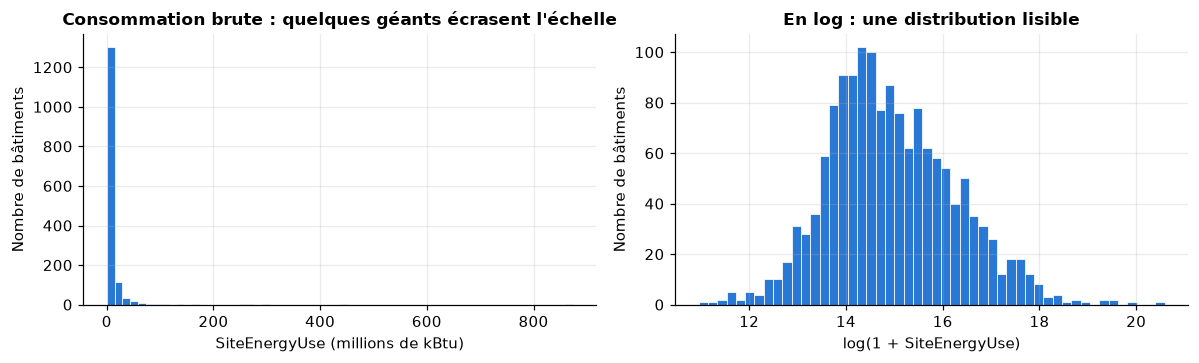

Médiane : 2,662,054 kBtu | moyenne : 8,805,959 kBtu | maximum : 873,923,712 kBtu
Asymétrie : 17.4 en brut, 0.40 en log


In [5]:
y_brut = df[TARGET]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(y_brut / 1e6, bins=60, color=BLEU, edgecolor="white", linewidth=0.5)
axes[0].set(
    title="Consommation brute : quelques géants écrasent l'échelle",
    xlabel="SiteEnergyUse (millions de kBtu)",
    ylabel="Nombre de bâtiments",
)
axes[1].hist(np.log1p(y_brut), bins=50, color=BLEU, edgecolor="white", linewidth=0.5)
axes[1].set(
    title="En log : une distribution lisible",
    xlabel="log(1 + SiteEnergyUse)",
    ylabel="Nombre de bâtiments",
)
plt.tight_layout()
plt.savefig(FIG / "02a_cible_avant.png", bbox_inches="tight")
plt.show()
print(
    f"Médiane : {y_brut.median():,.0f} kBtu | moyenne : {y_brut.mean():,.0f} kBtu | maximum : {y_brut.max():,.0f} kBtu"
)
print(f"Asymétrie : {y_brut.skew():.1f} en brut, {np.log1p(y_brut).skew():.2f} en log")

La consommation va de 57 000 à 874 millions de kBtu, avec une asymétrie très forte. Avant le choix d'une règle pour les valeurs extrêmes, comparaison de plusieurs méthodes de détection, dont le **z-score** : il mesure l'écart à la moyenne en nombre d'écarts-types, et au-delà de |z| > 3 un bâtiment est considéré comme extrême.

In [6]:
from scipy.stats import zscore

conso = df[TARGET]
log_conso = np.log1p(conso)
q1_l, q3_l = log_conso.quantile([0.25, 0.75])
iqr_l = q3_l - q1_l
p1, p99 = df["SiteEUI(kBtu/sf)"].quantile([0.01, 0.99])

methodes = {
    "Z-score > 3 sur la consommation brute": np.abs(zscore(conso)) > 3,
    "Z-score > 3 sur la consommation en log": np.abs(zscore(log_conso)) > 3,
    "IQR (1,5) sur la consommation en log": ~log_conso.between(
        q1_l - 1.5 * iqr_l, q3_l + 1.5 * iqr_l
    ),
    "Intensité hors [P1 ; P99]": ~df["SiteEUI(kBtu/sf)"].between(p1, p99),
}
comparaison_outliers = pd.DataFrame(
    {
        "Bâtiments signalés": {nom: int(m.sum()) for nom, m in methodes.items()},
        "dont sous la moyenne": {
            nom: int((m & (log_conso < log_conso.mean())).sum())
            for nom, m in methodes.items()
        },
        "% du jeu": {nom: round(m.mean() * 100, 1) for nom, m in methodes.items()},
    }
)
inclus = (
    methodes["Z-score > 3 sur la consommation en log"]
    & ~methodes["IQR (1,5) sur la consommation en log"]
).sum() == 0
print(
    f"Les bâtiments signalés par le z-score sur le log sont tous signalés par l'IQR : {inclus}"
)
comparaison_outliers

Les bâtiments signalés par le z-score sur le log sont tous signalés par l'IQR : True


,Bâtiments signalés,dont sous la moyenne,% du jeu
Z-score > 3 sur la consommation brute,10,0,0.7
Z-score > 3 sur la consommation en log,8,1,0.5
"IQR (1,5) sur la consommation en log",12,2,0.8
Intensité hors [P1 ; P99],30,15,2.0


In [7]:
# Les bâtiments signalés par le z-score sur la consommation brute : uniquement les plus gros consommateurs
(
    df.loc[
        methodes["Z-score > 3 sur la consommation brute"],
        ["PrimaryPropertyType", "PropertyGFABuilding(s)", TARGET],
    ].sort_values(TARGET, ascending=False)
)

,PrimaryPropertyType,PropertyGFABuilding(s),SiteEnergyUse(kBtu)
1463,University,9320156,873923712.0
30,Mixed Use Property,494835,448385312.0
131,Hospital,1158691,293090784.0
536,Hospital,1765970,291614432.0
480,Other,429405,274682208.0
102,Hospital,879000,253832464.0
1458,Hospital,374466,163945984.0
129,Hospital,597519,143423024.0
278,Other,535947,131373880.0
875,University,2200000,114648520.0


**Ce que montre la comparaison :**
- sur la consommation **brute**, le z-score ne signale que les plus gros consommateurs (hôpitaux, universités) et aucun bâtiment anormalement bas. Le z-score suppose une distribution proche de la normale ; ici, la moyenne et l'écart-type sont eux-mêmes tirés par ces très grands bâtiments. Il retirerait donc des bâtiments réels plutôt que des anomalies ;
- sur la consommation **en log**, le z-score devient cohérent : tous les bâtiments qu'il signale le sont aussi par la règle IQR, qui est un peu plus stricte et ne dépend pas de la moyenne ;
- l'intensité énergétique repère un autre type d'anomalie : une consommation incohérente avec la taille du bâtiment.

**Règles retenues : l'intensité entre P1 et P99, puis l'IQR sur le log.** Le z-score sur le log sert de contrôle. Même quand ces valeurs ne sont pas fausses, elles risquent de déformer le modèle ; attention à ne pas trop réduire le jeu.

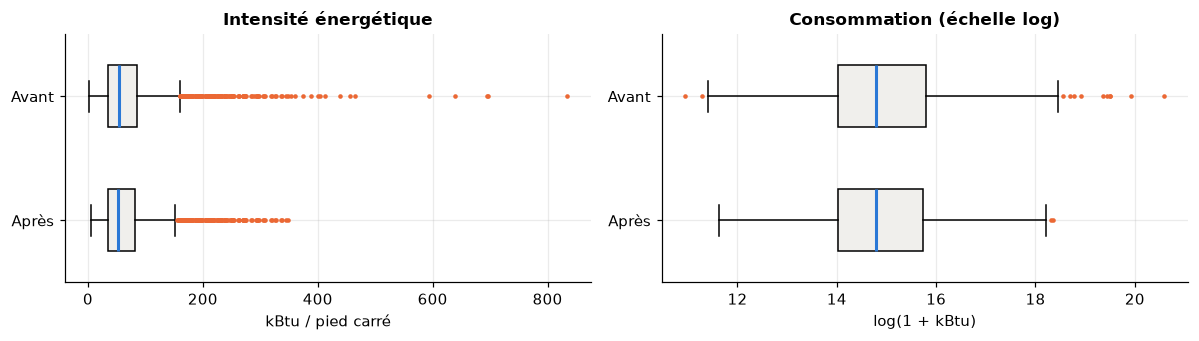

Jeu final : 1,454 bâtiments, soit 87.2 % des 1 668 bâtiments non résidentiels


,Étape,Avant,Après,Supprimés
0,Intensité entre P1 (5.1) et P99 (349.4) kBtu/pi²,1495,1465,30
1,"Consommation (log) dans [Q1 − 1,5 IQR ; Q3 + 1...",1465,1454,11


In [8]:
suivi = []


def etape(data, masque, libelle):
    """Applique un filtre et enregistre le nombre de lignes avant/après."""
    avant = len(data)
    data = data[masque]
    suivi.append(
        {
            "Étape": libelle,
            "Avant": avant,
            "Après": len(data),
            "Supprimés": avant - len(data),
        }
    )
    return data


eui_avant, log_avant = df["SiteEUI(kBtu/sf)"].copy(), np.log1p(df[TARGET])
df = etape(
    df,
    df["SiteEUI(kBtu/sf)"].between(p1, p99),
    f"Intensité entre P1 ({p1:.1f}) et P99 ({p99:.1f}) kBtu/pi²",
)
log_y = np.log1p(df[TARGET])
q1, q3 = log_y.quantile([0.25, 0.75])
iqr = q3 - q1
df = etape(
    df,
    log_y.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr),
    "Consommation (log) dans [Q1 − 1,5 IQR ; Q3 + 1,5 IQR]",
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (avant, apres, titre, xlabel) in zip(
    axes,
    [
        (
            eui_avant,
            df["SiteEUI(kBtu/sf)"],
            "Intensité énergétique",
            "kBtu / pied carré",
        ),
        (
            log_avant,
            np.log1p(df[TARGET]),
            "Consommation (échelle log)",
            "log(1 + kBtu)",
        ),
    ],
):
    ax.boxplot(
        [apres, avant],
        orientation="horizontal",
        widths=0.5,
        tick_labels=["Après", "Avant"],
        patch_artist=True,
        boxprops=dict(facecolor=GRIS),
        medianprops=dict(color=BLEU, linewidth=2),
        flierprops=dict(
            marker="o", markersize=3, markerfacecolor=ORANGE, markeredgecolor="none"
        ),
    )
    ax.set(title=titre, xlabel=xlabel)
plt.tight_layout()
plt.savefig(FIG / "01_outliers.png", bbox_inches="tight")
plt.show()

# L'intensité a servi à filtrer : elle n'est pas une feature (fuite de données)
df = df.drop(columns=["SiteEUI(kBtu/sf)"]).reset_index(drop=True)
print(
    f"Jeu final : {len(df):,} bâtiments, soit {len(df) / 1668 * 100:.1f} % des 1 668 bâtiments non résidentiels"
)
pd.DataFrame(suivi)

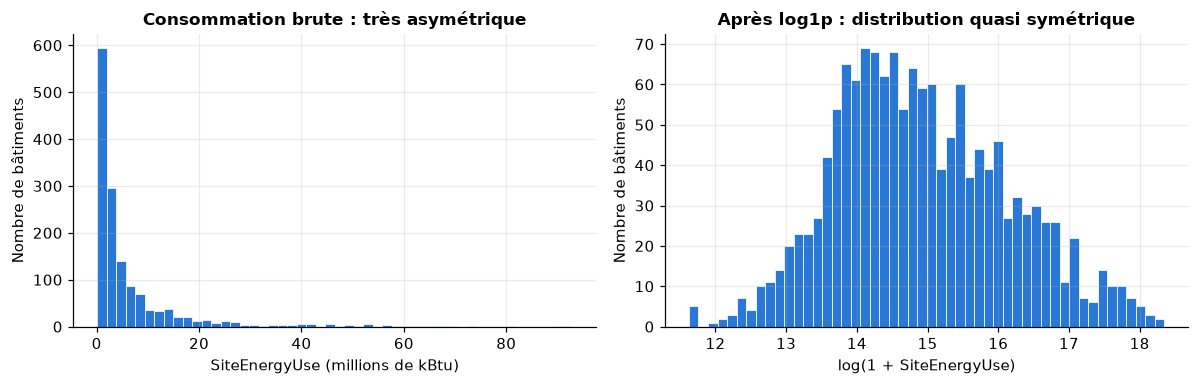

,Brute (kBtu),log1p
count,1454.00,1454.00
mean,6616768.60,14.92
std,10771452.61,1.22
min,111969.70,11.63
25%,1243146.31,14.03
50%,2641331.00,14.79
75%,6859031.88,15.74
max,92937640.00,18.35
asymétrie,3.61,0.30


In [9]:
y = df[TARGET]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(y / 1e6, bins=50, color=BLEU, edgecolor="white", linewidth=0.5)
axes[0].set(
    title="Consommation brute : très asymétrique",
    xlabel="SiteEnergyUse (millions de kBtu)",
    ylabel="Nombre de bâtiments",
)
axes[1].hist(np.log1p(y), bins=50, color=BLEU, edgecolor="white", linewidth=0.5)
axes[1].set(
    title="Après log1p : distribution quasi symétrique",
    xlabel="log(1 + SiteEnergyUse)",
    ylabel="Nombre de bâtiments",
)
plt.tight_layout()
plt.savefig(FIG / "02_cible.png", bbox_inches="tight")
plt.show()

stats = pd.DataFrame({"Brute (kBtu)": y.describe(), "log1p": np.log1p(y).describe()})
stats.loc["asymétrie"] = [y.skew(), np.log1p(y).skew()]
stats.round(2)

**Lecture de la cible :** même après le retrait des valeurs extrêmes, la consommation brute reste très asymétrique : la moyenne (6,6 millions de kBtu) est 2,5 fois plus élevée que la médiane (2,6 millions), car quelques très grands bâtiments tirent la moyenne vers le haut. La médiane représente mieux un bâtiment type. Après `log1p`, l'asymétrie passe de 3,6 à 0,3 : la distribution devient quasi symétrique.

**Modélisation de log(1 + consommation)**, avec retour en kBtu par `expm1` pour interpréter les erreurs. Conséquence à garder en tête : un écart de 0,69 en log correspond à un facteur 2 en kBtu.

#### 3. Features redondantes : matrice de corrélation de Pearson

Calcul de la matrice de Pearson avec `corr()` sur les features numériques, affichée avec une heatmap Seaborn. Les surfaces sont passées au log, sinon quelques très grands bâtiments dominent le calcul. Quand deux features dépassent |0,7|, elles portent la même information : fusion ou suppression de l'une des deux.

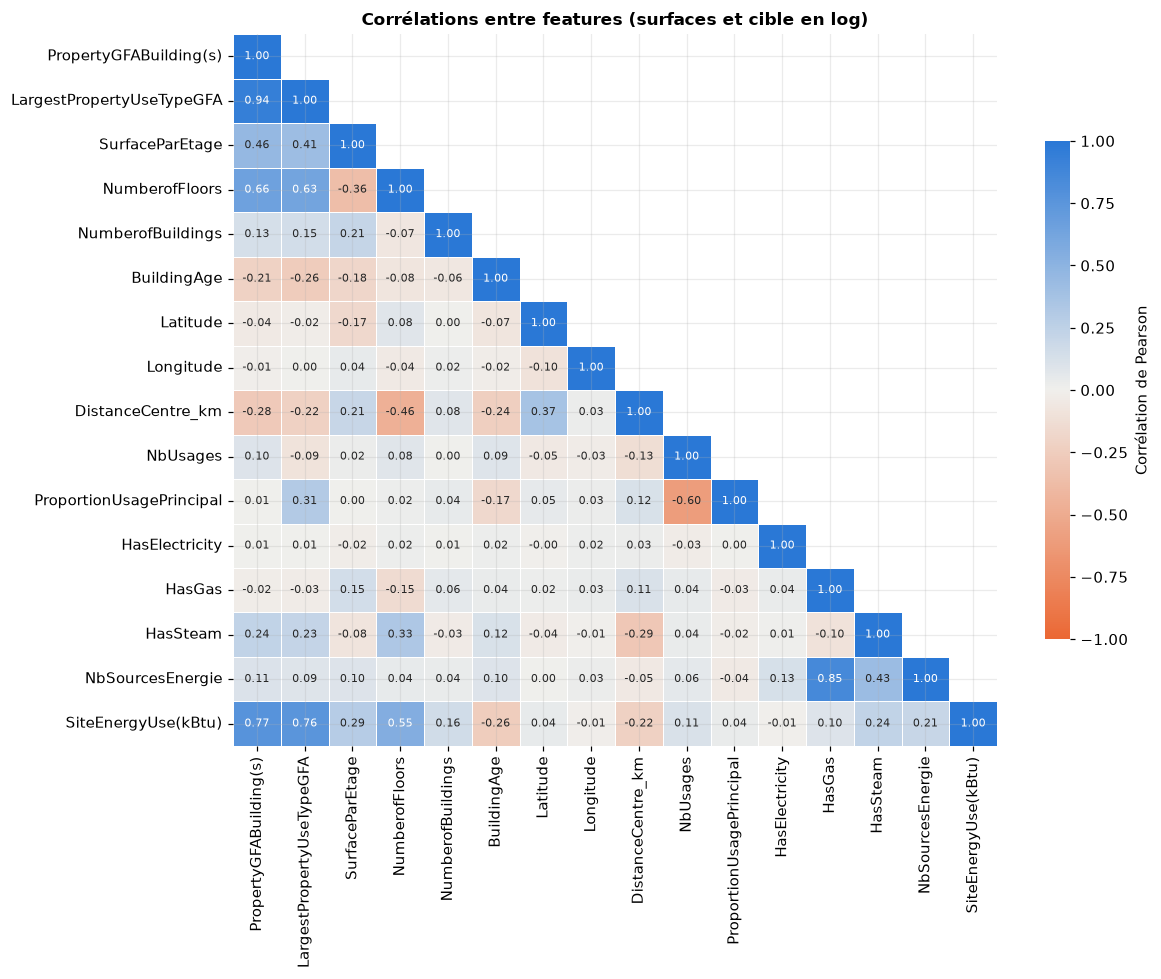

Paires de features avec |r| > 0,7 :
  PropertyGFABuilding(s)       – LargestPropertyUseTypeGFA    r = 0.94
  HasGas                       – NbSourcesEnergie             r = 0.85

Part des bâtiments raccordés à l'électricité : 99.8 %

Corrélation des features avec la cible (log) :
PropertyGFABuilding(s)       0.77
LargestPropertyUseTypeGFA    0.76
NumberofFloors               0.55
SurfaceParEtage              0.29
HasSteam                     0.24
NbSourcesEnergie             0.21
NumberofBuildings            0.16
NbUsages                     0.11
HasGas                       0.10
Latitude                     0.04
ProportionUsagePrincipal     0.04
HasElectricity              -0.01
Longitude                   -0.01
DistanceCentre_km           -0.22
BuildingAge                 -0.26


In [10]:
NUM_CORR = [
    "PropertyGFABuilding(s)",
    "LargestPropertyUseTypeGFA",
    "SurfaceParEtage",
    "NumberofFloors",
    "NumberofBuildings",
    "BuildingAge",
    "Latitude",
    "Longitude",
    "DistanceCentre_km",
    "NbUsages",
    "ProportionUsagePrincipal",
    "HasElectricity",
    "HasGas",
    "HasSteam",
    "NbSourcesEnergie",
]
A_LOG = [
    "PropertyGFABuilding(s)",
    "LargestPropertyUseTypeGFA",
    "SurfaceParEtage",
    "NumberofFloors",
    "NumberofBuildings",
    TARGET,
]

mat = df[NUM_CORR + [TARGET]].copy()
mat[A_LOG] = np.log1p(mat[A_LOG])
corr = mat.corr()

cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "div", [ORANGE, GRIS, BLEU]
)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr,
    mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
    cmap=cmap,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Corrélation de Pearson", "shrink": 0.7},
    ax=ax,
)
ax.set_title("Corrélations entre features (surfaces et cible en log)")
plt.tight_layout()
plt.savefig(FIG / "05_correlations.png", bbox_inches="tight")
plt.show()

paires = [
    (a, b, round(corr.loc[a, b], 2))
    for i, a in enumerate(NUM_CORR)
    for b in NUM_CORR[i + 1 :]
    if abs(corr.loc[a, b]) > 0.7
]
print("Paires de features avec |r| > 0,7 :")
for a, b, r in paires:
    print(f"  {a:28s} – {b:28s} r = {r}")
print(
    f"\nPart des bâtiments raccordés à l'électricité : {df['HasElectricity'].mean() * 100:.1f} %"
)
print("\nCorrélation des features avec la cible (log) :")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(2).to_string())

**Décisions :**

| Feature(s) | Constat | Décision |
|---|---|---|
| `PropertyGFABuilding(s)` / `LargestPropertyUseTypeGFA` | quasi identiques (r > 0,9) | conservation de la surface bâtie ; la surface de l'usage principal est **fusionnée** dans le ratio `ProportionUsagePrincipal` |
| `HasGas` / `NbSourcesEnergie` | r > 0,8 | suppression de `NbSourcesEnergie` ; `HasGas` et `HasSteam` sont plus lisibles |
| `HasElectricity` | presque tous les bâtiments sont raccordés (variance quasi nulle) | supprimée |
| `Latitude` / `Longitude` | information géographique brute | **fusionnées** dans `DistanceCentre_km`, complétée par le quartier |

La surface est très corrélée à la cible (r ≈ 0,77) : ce n'est pas un problème, c'est le signal que le modèle doit exploiter. Restent **6 nouvelles features** : `BuildingAge`, `SurfaceParEtage`, `NbUsages`, `ProportionUsagePrincipal`, `HasGas` / `HasSteam` et `DistanceCentre_km`.

In [11]:
df = df.drop(
    columns=[
        "LargestPropertyUseTypeGFA",
        "NbSourcesEnergie",
        "HasElectricity",
        "Latitude",
        "Longitude",
    ]
)
print(f"{df.shape[1]} colonnes restantes :", ", ".join(df.columns))

17 colonnes restantes : OSEBuildingID, BuildingType, PrimaryPropertyType, Neighborhood, NumberofBuildings, NumberofFloors, PropertyGFABuilding(s), LargestPropertyUseType, ENERGYSTARScore, SiteEnergyUse(kBtu), BuildingAge, SurfaceParEtage, NbUsages, ProportionUsagePrincipal, HasGas, HasSteam, DistanceCentre_km


#### 4. Liens entre les features et la cible

Choix du graphique selon le type de variables : un **boxplot** pour croiser une feature qualitative et la cible, un **nuage de points** pour deux variables quantitatives, et un **pairplot** pour voir toutes les features numériques d'un coup.

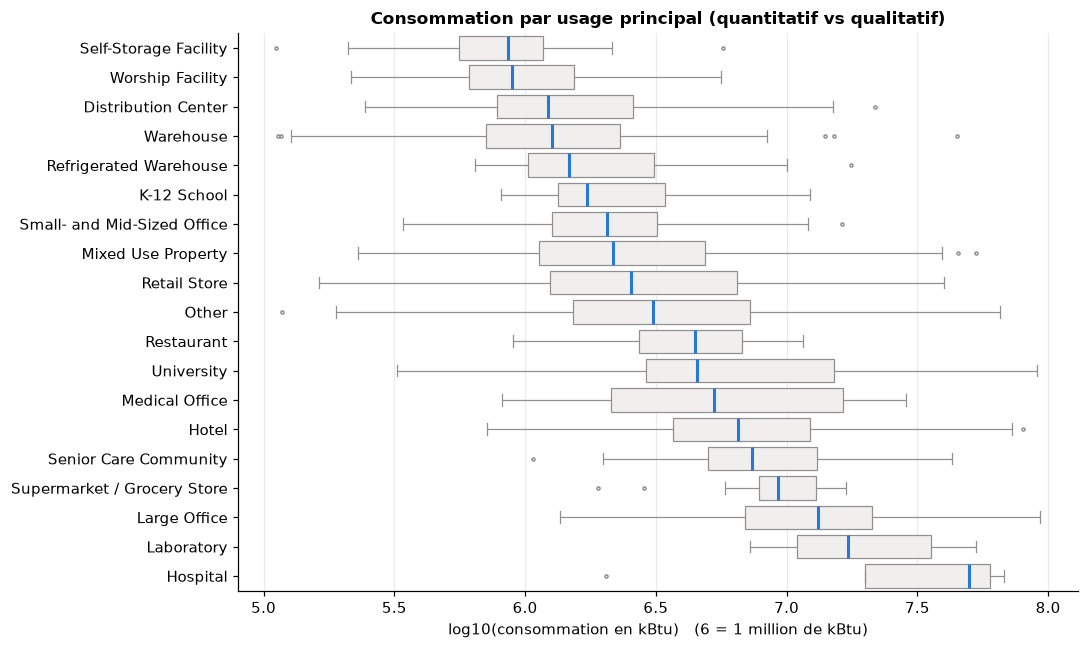

In [12]:
ordre = df.groupby("PrimaryPropertyType")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=df.assign(log10_conso=np.log10(df[TARGET])),
    y="PrimaryPropertyType",
    x="log10_conso",
    order=ordre,
    color=GRIS,
    linewidth=0.8,
    fliersize=2,
    medianprops=dict(color=BLEU, linewidth=2),
    ax=ax,
)
ax.set(
    title="Consommation par usage principal (quantitatif vs qualitatif)",
    xlabel="log10(consommation en kBtu)   (6 = 1 million de kBtu)",
    ylabel="",
)
plt.tight_layout()
plt.savefig(FIG / "03_conso_par_usage.png", bbox_inches="tight")
plt.show()

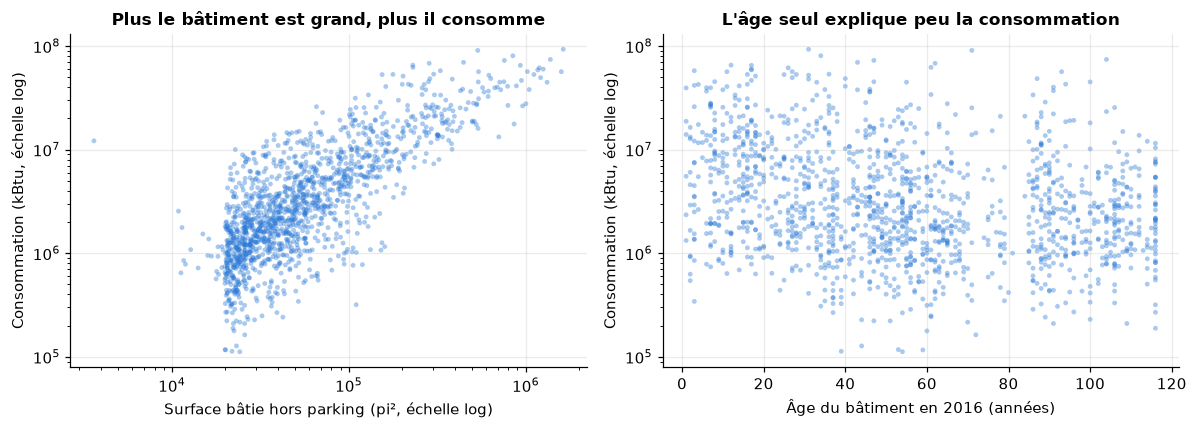

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(
    df["PropertyGFABuilding(s)"],
    df[TARGET],
    s=10,
    alpha=0.4,
    color=BLEU,
    edgecolors="none",
)
axes[0].set(
    xscale="log",
    yscale="log",
    title="Plus le bâtiment est grand, plus il consomme",
    xlabel="Surface bâtie hors parking (pi², échelle log)",
    ylabel="Consommation (kBtu, échelle log)",
)
axes[1].scatter(
    df["BuildingAge"], df[TARGET], s=10, alpha=0.4, color=BLEU, edgecolors="none"
)
axes[1].set(
    yscale="log",
    title="L'âge seul explique peu la consommation",
    xlabel="Âge du bâtiment en 2016 (années)",
    ylabel="Consommation (kBtu, échelle log)",
)
plt.tight_layout()
plt.savefig(FIG / "04_surface_age.png", bbox_inches="tight")
plt.show()

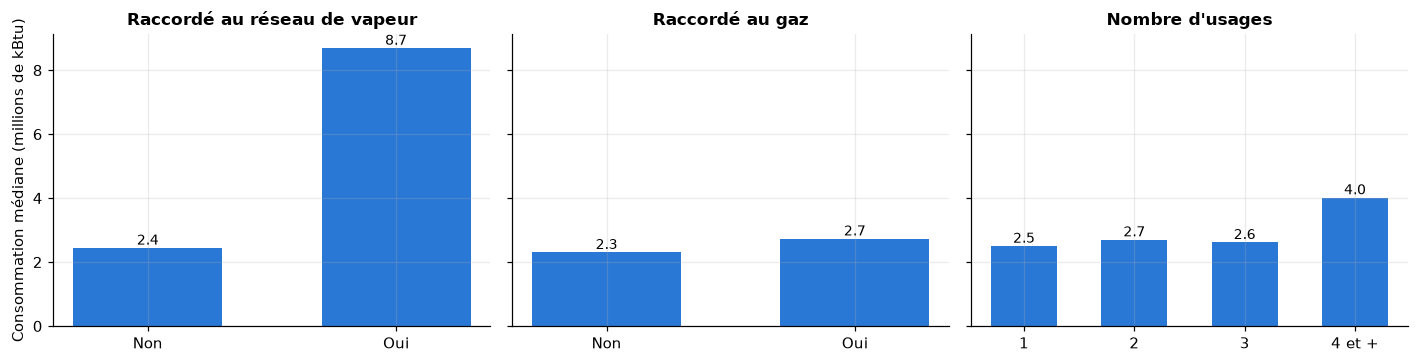

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
vues = [
    (df["HasSteam"].map({0: "Non", 1: "Oui"}), "Raccordé au réseau de vapeur"),
    (df["HasGas"].map({0: "Non", 1: "Oui"}), "Raccordé au gaz"),
    (
        df["NbUsages"].clip(upper=4).map(lambda n: "4 et +" if n == 4 else str(n)),
        "Nombre d'usages",
    ),
]
for ax, (groupe, titre) in zip(axes, vues):
    med = (df[TARGET] / 1e6).groupby(groupe).median()
    ax.bar(med.index, med.values, color=BLEU, width=0.6)
    for x, v in zip(med.index, med.values):
        ax.text(x, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set(title=titre, xlabel="")
axes[0].set_ylabel("Consommation médiane (millions de kBtu)")
plt.tight_layout()
plt.savefig(FIG / "06_tendances_features.png", bbox_inches="tight")
plt.show()

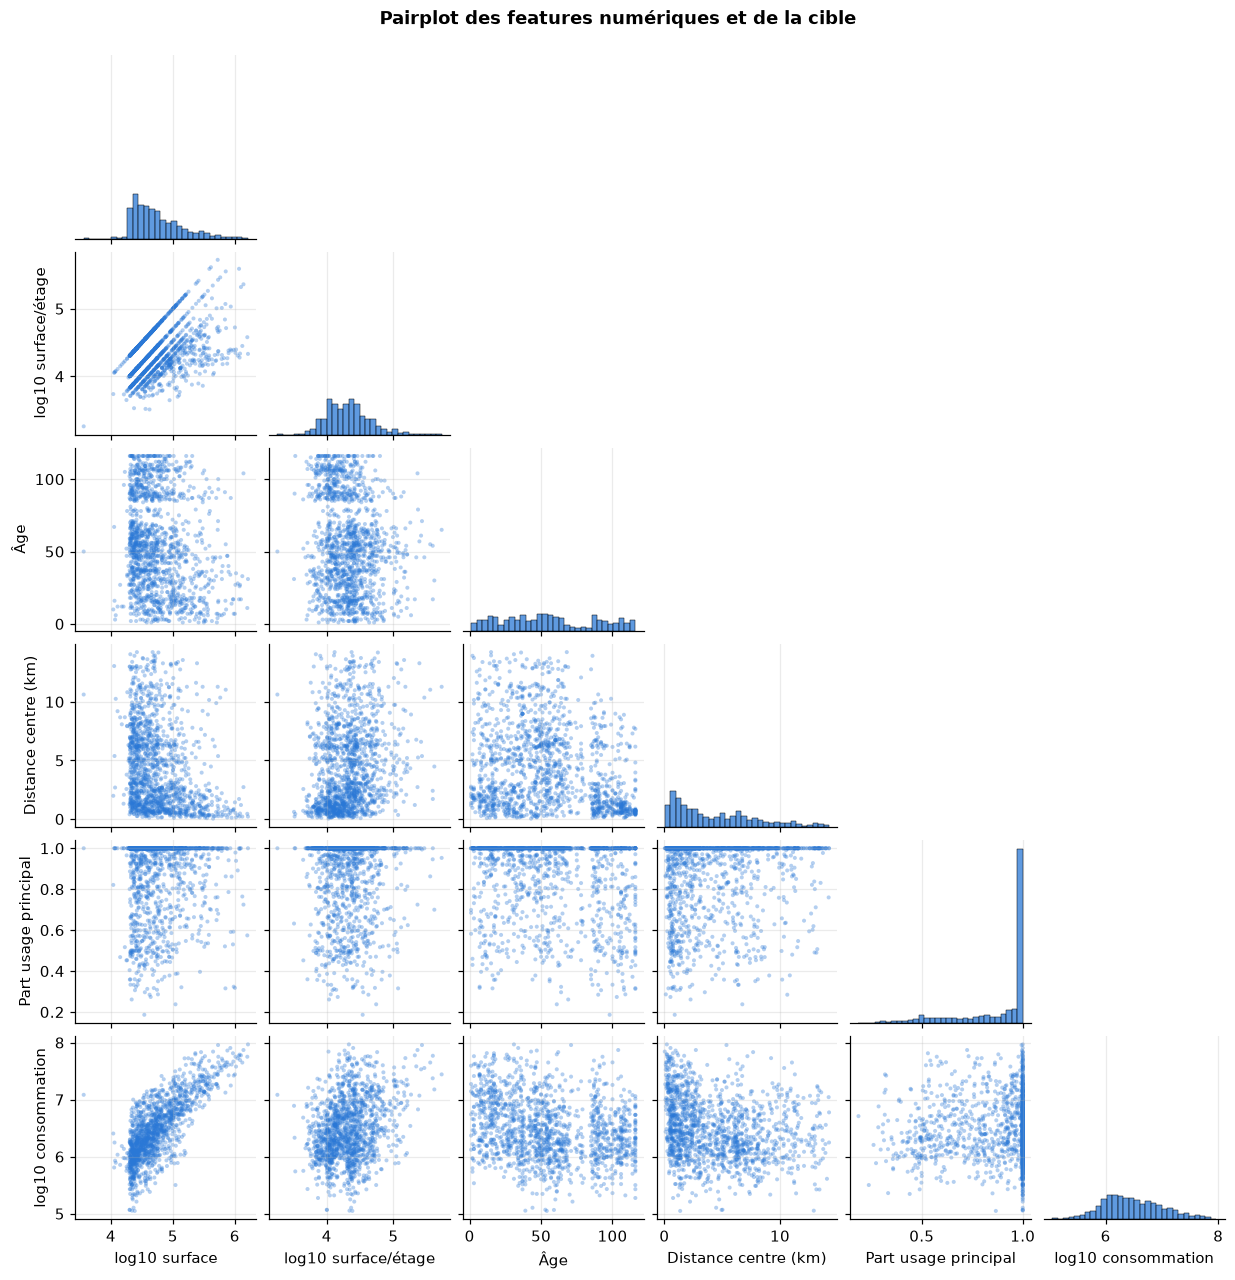

In [15]:
paire = pd.DataFrame(
    {
        "log10 surface": np.log10(df["PropertyGFABuilding(s)"]),
        "log10 surface/étage": np.log10(df["SurfaceParEtage"]),
        "Âge": df["BuildingAge"],
        "Distance centre (km)": df["DistanceCentre_km"],
        "Part usage principal": df["ProportionUsagePrincipal"],
        "log10 consommation": np.log10(df[TARGET]),
    }
)
g = sns.pairplot(
    paire,
    corner=True,
    diag_kind="hist",
    height=1.9,
    plot_kws=dict(s=7, alpha=0.35, edgecolor="none", color=BLEU),
    diag_kws=dict(bins=30, color=BLEU),
)
g.fig.suptitle(
    "Pairplot des features numériques et de la cible", y=1.02, fontweight="bold"
)
plt.savefig(FIG / "07_pairplot_features.png", bbox_inches="tight")
plt.show()

**Points clés :**
- la **surface** est le facteur le plus évident : en échelle log, la consommation la suit presque linéairement ; c'est la seule feature numérique nettement liée à la cible dans le pairplot ;
- **l'usage** change beaucoup la consommation, même à surface égale : les hôpitaux, laboratoires et supermarchés sont en haut, les garde-meubles, lieux de culte et entrepôts en bas ;
- les bâtiments raccordés au réseau de vapeur (souvent de grands immeubles du centre-ville) consomment environ 3,5 fois plus en médiane. L'effet du gaz est faible, et la mixité des usages ne se voit qu'à partir de 4 usages ;
- **l'âge** et la **distance au centre** seuls expliquent peu : leur poids réel sera mesuré par le modèle, en combinaison avec les autres features.

#### 5. Séparation X / y et découpage 60 / 20 / 20 stratifié

`X` est un DataFrame contenant uniquement les 14 features, `y` une Series contenant log(1 + consommation). Découpage en **train (60 %)**, **validation (20 %)** et **test (20 %)**. En régression il n'y a pas de classes : stratification sur les **déciles de la cible** (`pd.qcut`), pour que chaque jeu ait la même répartition de petits et de grands consommateurs.

In [16]:
NUM_LOG = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "NumberofBuildings",
    "SurfaceParEtage",
]
NUM = ["BuildingAge", "DistanceCentre_km", "NbUsages", "ProportionUsagePrincipal"]
BIN = ["HasGas", "HasSteam"]
CAT = ["BuildingType", "PrimaryPropertyType", "LargestPropertyUseType", "Neighborhood"]
FEATURES = NUM_LOG + NUM + BIN + CAT

X = df[FEATURES]  # DataFrame des features
y = np.log1p(df[TARGET])  # Series de la cible : log(1 + consommation)

tranches = pd.qcut(y, q=10, labels=False)
X_tmp, X_test, y_tmp, y_test, t_tmp, _ = train_test_split(
    X, y, tranches, test_size=0.20, stratify=tranches, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=t_tmp, random_state=RANDOM_STATE
)  # 0,25 x 80 % = 20 %

resume = pd.DataFrame(
    {
        nom: {
            "Bâtiments": len(ys),
            "Part (%)": round(len(ys) / len(y) * 100),
            "Moyenne log(y)": ys.mean(),
            "Écart-type log(y)": ys.std(),
            "Médiane (kBtu)": np.expm1(ys.median()),
        }
        for nom, ys in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]
    }
).T
print(f"X : {X.shape[0]:,} bâtiments x {X.shape[1]} features | y : {type(y).__name__}")
resume.round(2)

X : 1,454 bâtiments x 14 features | y : Series


,Bâtiments,Part (%),Moyenne log(y),Écart-type log(y),Médiane (kBtu)
Train,872.0,60.0,14.92,1.24,2644279.10
Validation,291.0,20.0,14.92,1.24,2619088.50
Test,291.0,20.0,14.90,1.18,2640980.25


Les trois jeux ont la même distribution de consommation : c'est l'effet de la stratification. **Le jeu de test est mis de côté et n'est plus utilisé jusqu'à l'évaluation finale.**

#### 6. Encodage des features catégorielles et pipeline de préparation


Les 4 features catégorielles sont **nominales** : choix du `OneHotEncoder`. Pour limiter le nombre de colonnes, les catégories de moins de 10 bâtiments sont regroupées (`min_frequency=10`). Ce seuil d'effectif est préféré à `max_categories`, qui fixe un nombre de colonnes arbitraire : une catégorie de moins de 10 bâtiments n'offre pas assez d'exemples pour que le modèle en apprenne un effet fiable.




In [17]:
df.PrimaryPropertyType.value_counts()

PrimaryPropertyType
Small- and Mid-Sized Office    285
Other                          220
Warehouse                      177
Large Office                   169
Mixed Use Property              97
Retail Store                    85
Hotel                           75
Worship Facility                69
Distribution Center             50
K-12 School                     50
Medical Office                  38
Supermarket / Grocery Store     38
Self-Storage Facility           24
University                      22
Senior Care Community           20
Refrigerated Warehouse          12
Restaurant                      11
Laboratory                       8
Hospital                         4
Name: count, dtype: int64

In [18]:
# Encodage OneHot de l'usage principal : une colonne 0/1 par usage, les usages de moins de 10 bâtiments sont regroupés
exemple = OneHotEncoder(
    handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False
)
usages_encodes = pd.DataFrame(
    exemple.fit_transform(df[["PrimaryPropertyType"]]).astype(int),
    columns=exemple.get_feature_names_out(),
    index=df.index,
)

print(
    f"{df['PrimaryPropertyType'].nunique()} usages -> {usages_encodes.shape[1]} colonnes"
)
print(
    "Usages regroupés (moins de 10 bâtiments) :",
    list(exemple.infrequent_categories_[0]),
)
usages_encodes.head()

19 usages -> 18 colonnes
Usages regroupés (moins de 10 bâtiments) : ['Hospital', 'Laboratory']


,PrimaryPropertyType_Distribution Center,PrimaryPropertyType_Hotel,PrimaryPropertyType_K-12 School,PrimaryPropertyType_Large Office,PrimaryPropertyType_Medical Office,PrimaryPropertyType_Mixed Use Property,PrimaryPropertyType_Other,PrimaryPropertyType_Refrigerated Warehouse,PrimaryPropertyType_Restaurant,PrimaryPropertyType_Retail Store,PrimaryPropertyType_Self-Storage Facility,PrimaryPropertyType_Senior Care Community,PrimaryPropertyType_Small- and Mid-Sized Office,PrimaryPropertyType_Supermarket / Grocery Store,PrimaryPropertyType_University,PrimaryPropertyType_Warehouse,PrimaryPropertyType_Worship Facility,PrimaryPropertyType_infrequent_sklearn
0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


**Lecture :** sur les 1 454 bâtiments, les 19 usages principaux deviennent **18 colonnes 0/1** : chaque bâtiment a un seul 1, dans la colonne de son usage. Les deux usages de moins de 10 bâtiments, Hospital (4) et Laboratory (8), sont regroupés dans une seule colonne `PrimaryPropertyType_infrequent_sklearn` (12 bâtiments). Avec un `LabelEncoder`, ces 19 usages seraient devenus une seule colonne d'entiers de 0 à 18, dans l'ordre alphabétique : le modèle aurait lu un ordre qui n'existe pas. Le `LabelEncoder` sert à l'inverse à encoder une cible de classification ; pour une feature réellement ordonnée (par exemple une note faible / moyenne / élevée), l'outil adapté est l'`OrdinalEncoder`, avec un ordre explicite.

**Dans le pipeline**, l'encodeur est ajusté sur le train seulement (872 bâtiments). Les effectifs y sont plus petits, donc davantage de catégories passent sous le seuil de 10 :

| Feature | Catégories dans le train | Colonnes après encodage | Catégories regroupées |
|---|---|---|---|
| `BuildingType` | 5 | 4 | 2 (Nonresidential WA, SPS-District K-12) |
| `PrimaryPropertyType` | 19 | 16 | 4 (Hospital, Laboratory, Refrigerated Warehouse, Restaurant) |
| `LargestPropertyUseType` | 46 | 16 | 31 usages rares |
| `Neighborhood` | 13 | 13 | aucune |

Les 4 features catégorielles donnent donc 49 colonnes. Avec les 11 colonnes numériques et binaires (dont l'indicateur `EtagesNonRenseignes`), les 14 features deviennent **60 colonnes**. Comme l'encodeur est appris sur le train, le jeu de test n'influence pas la liste des catégories : il n'y a pas de fuite.

**Étages non renseignés ou non plausibles.** 11 bâtiments ont un nombre d'étages manquant ou incohérent (10 déclarent 0 étage, un lieu de culte déclare 99 étages pour 21 948 pi²). Dans le notebook 1, recherche d'autres relevés à la même adresse, sur la même parcelle ou aux mêmes coordonnées : cette piste ne permet de corriger aucune valeur de façon fiable. Une imputation est donc nécessaire.

Choix de la méthode par un test sur des bâtiments dont le nombre d'étages est **connu** : la valeur est masquée, chaque méthode la devine, puis comparaison avec la vraie valeur. Les statistiques sont apprises sur 80 % des bâtiments du train et testées sur les 20 % restants, en 5 répétitions. Comparaison des méthodes les plus courantes sur ce jeu de données (remplacer par 1, médiane globale, moyenne par quartier) avec deux méthodes qui tiennent compte de l'usage.

In [19]:
connus = X_train[X_train["NumberofFloors"].notna()].reset_index(drop=True)
connus = connus.assign(
    surface_etage=connus["PropertyGFABuilding(s)"] / connus["NumberofFloors"]
)
erreurs = {}
for app, essai in KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(
    connus
):
    a, b = connus.iloc[app], connus.iloc[essai]
    mediane = a["NumberofFloors"].median()
    estimations = {
        "Remplacer par 1": np.ones(len(b)),
        "Médiane globale": np.full(len(b), mediane),
        "Moyenne par quartier": b["Neighborhood"]
        .map(a.groupby("Neighborhood")["NumberofFloors"].mean().round())
        .fillna(a["NumberofFloors"].mean())
        .values,
        "Médiane par type d'usage (retenue)": b["PrimaryPropertyType"]
        .map(a.groupby("PrimaryPropertyType")["NumberofFloors"].median())
        .fillna(mediane)
        .values,
        "Surface ÷ surface par étage du type": np.clip(
            np.round(
                b["PropertyGFABuilding(s)"]
                / b["PrimaryPropertyType"]
                .map(a.groupby("PrimaryPropertyType")["surface_etage"].median())
                .fillna(a["surface_etage"].median())
            ),
            1,
            None,
        ).values,
    }
    for nom, estimation in estimations.items():
        erreurs.setdefault(nom, []).append(
            pd.DataFrame(
                {
                    "vrai": b["NumberofFloors"].values,
                    "erreur": np.abs(estimation - b["NumberofFloors"].values),
                }
            )
        )
bilan = {}
for nom, morceaux in erreurs.items():
    e = pd.concat(morceaux)
    bilan[nom] = {
        "Erreur moyenne (étages)": e["erreur"].mean(),
        "Juste à ±1 étage (%)": (e["erreur"] <= 1).mean() * 100,
        "Erreur moyenne au-delà de 10 étages": e.loc[e["vrai"] > 10, "erreur"].mean(),
    }
display(pd.DataFrame(bilan).T.round(2).sort_values("Erreur moyenne (étages)"))

# Valeurs que donneraient les deux méthodes qui tiennent compte de l'usage, pour les bâtiments concernés
mediane_type = connus.groupby("PrimaryPropertyType")["NumberofFloors"].median()
surface_type = connus.groupby("PrimaryPropertyType")["surface_etage"].median()
concernes = X[X["NumberofFloors"].isna()]
pd.DataFrame(
    {
        "Usage": concernes["PrimaryPropertyType"],
        "Bâtiments": concernes["NumberofBuildings"],
        "Surface (pi²)": concernes["PropertyGFABuilding(s)"],
        "Médiane par type": concernes["PrimaryPropertyType"]
        .map(mediane_type)
        .fillna(connus["NumberofFloors"].median()),
        "Surface ÷ surface par étage du type": np.clip(
            np.round(
                concernes["PropertyGFABuilding(s)"]
                / concernes["PrimaryPropertyType"]
                .map(surface_type)
                .fillna(connus["surface_etage"].median())
            ),
            1,
            None,
        ),
    }
).reset_index(drop=True)

,Erreur moyenne (étages),Juste à ±1 étage (%),Erreur moyenne au-delà de 10 étages
Surface ÷ surface par étage du type,2.28,64.43,7.78
Médiane par type d'usage (retenue),2.32,66.97,16.15
Moyenne par quartier,2.90,61.09,14.13
Médiane globale,3.01,61.89,21.06
Remplacer par 1,3.42,50.58,22.34


,Usage,Bâtiments,Surface (pi²),Médiane par type,Surface ÷ surface par étage du type
0,Hotel,1.0,934292,7.0,84.0
1,Medical Office,1.0,225982,3.0,13.0
2,Other,1.0,947987,2.0,43.0
3,Worship Facility,1.0,21948,2.0,1.0
4,Medical Office,1.0,274568,3.0,15.0
5,Other,10.0,230971,2.0,10.0
6,Warehouse,1.0,384772,1.0,12.0
7,Medical Office,1.0,30287,3.0,2.0
8,Small- and Mid-Sized Office,1.0,21931,3.0,2.0
9,Other,8.0,502030,2.0,23.0


**Ce que montre le test :**
- les méthodes les plus courantes sont les moins justes : remplacer par 1 ne trouve le bon nombre d'étages (à ±1 près) que pour un bâtiment sur deux et sous-estime fortement les immeubles ; la médiane globale et la moyenne par quartier font à peine mieux ;
- les deux méthodes qui tiennent compte de l'usage sont nettement meilleures et au coude-à-coude : la méthode par la surface a une erreur moyenne à peine plus faible (2,28 étages contre 2,32) et elle est bien meilleure sur les tours, mais la médiane par type d'usage est plus souvent juste à ±1 étage (67 % contre 64 %) ;
- surtout, la méthode par la surface suppose un bâtiment unique et compact. Sur les 11 bâtiments réels, elle donnerait des valeurs aberrantes : 84 étages à l'hôtel, 43 à un bâtiment « Other » de 948 000 pi², 12 à un entrepôt et 23 à un campus de 8 bâtiments.

**Méthode retenue : la médiane par type d'usage**, qui ne produit jamais de valeur aberrante, complétée par l'indicateur `EtagesNonRenseignes`. Ces 11 bâtiments ne représentent que 0,8 % du jeu : l'enjeu sur la performance est faible, mais la méthode reste cohérente pour un futur bâtiment sans nombre d'étages.

| Bloc | Colonnes | Transformations |
|---|---|---|
| Numériques asymétriques | surface bâtie, étages, nombre de bâtiments, surface par étage | imputation (médiane) → log1p → `StandardScaler` |
| Numériques | âge, distance au centre, nombre d'usages, part de l'usage principal | imputation (médiane) → `StandardScaler` |
| Binaires | `HasGas`, `HasSteam`, `EtagesNonRenseignes` | inchangées |
| Catégorielles | type de bâtiment, usage principal, plus grand usage, quartier | `OneHotEncoder(min_frequency=10)` |

Le **scaling** est nécessaire : les features ont des ordres de grandeur très différents (surfaces en centaines de milliers de pi², proportions entre 0 et 1), et la régression linéaire comme le SVR y sont sensibles. Il est sans effet sur les modèles à base d'arbres. Comme tout est dans un `Pipeline`, les médianes, moyennes et catégories sont apprises **sur le fold d'entraînement uniquement**, à chaque étape de la validation croisée : il n'y a pas de fuite.

In [20]:
class ImputationEtages(BaseEstimator, TransformerMixin):
    """Impute le nombre d'étages par la médiane du type d'usage (apprise au fit), recalcule la surface
    par étage et ajoute un indicateur de valeur imputée."""

    def __init__(self, groupe="PrimaryPropertyType", min_batiments=5):
        self.groupe = groupe
        self.min_batiments = min_batiments

    def fit(self, X, y=None):
        stats = X["NumberofFloors"].groupby(X[self.groupe]).agg(["median", "count"])
        self.medianes_ = stats.loc[
            stats["count"] >= self.min_batiments, "median"
        ].to_dict()
        self.mediane_globale_ = float(X["NumberofFloors"].median())
        return self

    def transform(self, X):
        X = X.copy()
        manquant = X["NumberofFloors"].isna()
        X["EtagesNonRenseignes"] = manquant.astype(int)
        X.loc[manquant, "NumberofFloors"] = (
            X.loc[manquant, self.groupe]
            .map(self.medianes_)
            .fillna(self.mediane_globale_)
        )
        X.loc[manquant, "SurfaceParEtage"] = (
            X.loc[manquant, "PropertyGFABuilding(s)"]
            / X.loc[manquant, "NumberofFloors"]
        )
        return X


preparation = ColumnTransformer(
    [
        (
            "log",
            make_pipeline(
                SimpleImputer(strategy="median"),
                FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                StandardScaler(),
            ),
            NUM_LOG,
        ),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
        ("bin", "passthrough", BIN + ["EtagesNonRenseignes"]),
        (
            "cat",
            make_pipeline(
                SimpleImputer(strategy="constant", fill_value="Inconnu"),
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=10,
                    sparse_output=False,
                ),
            ),
            CAT,
        ),
    ]
)


def pipeline(modele, prep=preparation):
    """Pipeline complet : imputation des étages, préparation, modèle."""
    return Pipeline(
        [("etages", ImputationEtages()), ("prep", prep), ("modele", modele)]
    )


etages = ImputationEtages().fit(X_train)
manquants = X_train[X_train["NumberofFloors"].isna()]
print(f"Bâtiments du train sans nombre d'étages plausible : {len(manquants)}")
print(
    pd.DataFrame(
        {
            "Type d'usage": manquants["PrimaryPropertyType"],
            "Étages imputés": etages.transform(manquants)["NumberofFloors"],
        }
    ).to_string(index=False)
)
n_colonnes = pipeline(LinearRegression())[:-1].fit(X_train).transform(X_train).shape[1]
print(f"\n{len(FEATURES)} features brutes  ->  {n_colonnes} colonnes après encodage")

Bâtiments du train sans nombre d'étages plausible : 6
               Type d'usage  Étages imputés
             Medical Office             3.0
                      Other             2.0
                      Other             2.0
             Medical Office             3.0
           Worship Facility             2.0
Small- and Mid-Sized Office             3.0

14 features brutes  ->  60 colonnes après encodage


### Comparaison de différents modèles supervisés

**Démarche, étape par étape :**
- **séparation train / test par validation croisée** : sur le train, une `KFold` à 5 folds ; chaque fold sert tour à tour de jeu de test ;
- **scaling** : intégré au pipeline, donc refait à chaque fold ;
- **entraînement** sur les 4 folds d'apprentissage, puis **inférence** (prédiction) sur le fold de test ;
- **métriques R², RMSE et MAE sur le train et sur le test** de chaque fold, plus l'erreur relative médiane ;
- **interprétation** : un écart important entre train et test signale un sur-apprentissage, un écart-type important entre folds un modèle instable.

| Métrique | Échelle | Lecture |
|---|---|---|
| **R²** | log | part de la variance expliquée (1 = parfait, 0 = pas mieux que la moyenne) |
| **RMSE** | log | erreur quadratique, pénalise les grosses erreurs ; en log, 0,5 correspond à un facteur d'environ 1,6 entre la prédiction et la réalité |
| **MAE** | kBtu | erreur absolue moyenne en kBtu, tirée par les plus gros bâtiments |
| **MdAPE** | % | erreur relative **médiane** : la moitié des bâtiments est estimée avec un écart inférieur à cette valeur |

**Lecture complémentaire : repérer les gros consommateurs.** L'objectif reste de prédire la consommation de chaque bâtiment, et ce sont les métriques ci-dessus qui guident les choix. Mais pour la ville, une prédiction sert aussi à savoir quels bâtiments relever en priorité. **Gros consommateur** : un bâtiment du quart le plus consommateur (seuil fixé sur le train) ; d'où une matrice de confusion : **TP** (gros consommateur repéré), **FN** (raté), **FP** (relevé inutile), **TN** (correctement écarté). Ce n'est pas une classification : le modèle reste une régression, et cette matrice n'en est qu'une lecture.

In [21]:
def mae_kbtu(y_true, y_pred):
    return mean_absolute_error(np.expm1(y_true), np.expm1(y_pred))


def mdape(y_true, y_pred):
    reel, pred = np.expm1(y_true), np.expm1(y_pred)
    return np.median(np.abs(pred - reel) / reel) * 100


SCORING = {
    "R2": "r2",
    "RMSE_log": "neg_root_mean_squared_error",
    "MAE_kBtu": make_scorer(mae_kbtu, greater_is_better=False),
    "MdAPE_%": make_scorer(mdape, greater_is_better=False),
}

SEUIL = y_train.quantile(0.75)  # gros consommateur = quart supérieur du train


def metriques(y_true, y_pred):
    """Métriques de régression + lecture « gros consommateurs » sur un jeu mis de côté."""
    tn, fp, fn, tp = confusion_matrix(
        y_true >= SEUIL, y_pred >= SEUIL, labels=[False, True]
    ).ravel()
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE_log": root_mean_squared_error(y_true, y_pred),
        "MAE_kBtu": mae_kbtu(y_true, y_pred),
        "MdAPE_%": mdape(y_true, y_pred),
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "Précision": tp / (tp + fp),
        "Rappel": tp / (tp + fn),
    }


def matrice(ax, y_true, y_pred, titre):
    """Matrice de confusion « gros consommateurs » annotée."""
    m = confusion_matrix(y_true >= SEUIL, y_pred >= SEUIL, labels=[True, False])
    ax.imshow(
        m,
        cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list(
            "b", ["#EEF3FA", BLEU]
        ),
    )
    noms_cases = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                f"{noms_cases[i][j]}\n{m[i, j]}",
                ha="center",
                va="center",
                fontsize=13,
                fontweight="bold",
                color="white" if m[i, j] > m.max() / 2 else "#1F2933",
            )
    ax.set_xticks([0, 1], ["Signalé", "Non signalé"])
    ax.set_yticks([0, 1], ["Gros\nconsommateur", "Autre"])
    ax.set_xlabel("Prédiction du modèle")
    ax.set_ylabel("Réalité")
    ax.grid(False)
    ax.set_title(titre)


CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
FOLDS, PREDICTIONS = {}, {}


def evaluer_modele(nom, estimateur, X=X_train, y=y_train, prep=preparation):
    """Validation croisée à 5 folds d'un modèle dans le pipeline complet : métriques sur le train et sur le
    test de chaque fold, R² de chaque fold et prédictions hors fold (inférence) pour les graphiques."""
    pipe = pipeline(estimateur, prep)
    res = cross_validate(
        pipe, X, y, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=-1
    )
    ligne = {"Modèle": nom}
    for m in SCORING:
        signe = 1 if m == "R2" else -1
        ligne[f"{m} train"] = signe * res[f"train_{m}"].mean()
        ligne[f"{m} CV"] = signe * res[f"test_{m}"].mean()
        ligne[f"{m} écart-type"] = res[f"test_{m}"].std()
    ligne["Temps d'entraînement (s)"] = res["fit_time"].mean()
    FOLDS[nom] = res["test_R2"]
    PREDICTIONS[nom] = cross_val_predict(pipe, X, y, cv=CV, n_jobs=-1)
    return ligne


def tableau(lignes):
    """Tableau lisible : métriques train / test (folds de validation croisée)."""
    t = pd.DataFrame(lignes).set_index("Modèle")
    return pd.DataFrame(
        {
            "R² train": t["R2 train"],
            "R² test (CV)": t["R2 CV"],
            "± écart-type": t["R2 écart-type"],
            "RMSE train": t["RMSE_log train"],
            "RMSE test (CV)": t["RMSE_log CV"],
            "MAE train (M kBtu)": t["MAE_kBtu train"] / 1e6,
            "MAE test (M kBtu)": t["MAE_kBtu CV"] / 1e6,
            "MdAPE test (%)": t["MdAPE_% CV"],
        }
    ).round(3)


print(f"Seuil « gros consommateur » : {np.expm1(SEUIL):,.0f} kBtu par an")

Seuil « gros consommateur » : 6,928,600 kBtu par an


#### Le modèle de référence, isolé

**La référence naïve.** Elle prédit la même valeur pour tous les bâtiments. Son seul réglage possible est la statistique utilisée : la moyenne ou la médiane.

In [22]:
tableau(
    [
        evaluer_modele("Référence : moyenne", DummyRegressor(strategy="mean")),
        evaluer_modele("Référence : médiane", DummyRegressor(strategy="median")),
    ]
)

,R² train,R² test (CV),± écart-type,RMSE train,RMSE test (CV),MAE train (M kBtu),MAE test (M kBtu),MdAPE test (%)
Modèle,,,,,,,,
Référence : moyenne,0.000,-0.019,0.017,1.235,1.238,5.395,5.413,76.032
Référence : médiane,-0.013,-0.036,0.044,1.243,1.248,5.379,5.402,72.369


La référence naïve **ne s'optimise pas** : passer de la moyenne à la médiane réduit un peu l'erreur médiane (72 % au lieu de 76 %) mais dégrade le R² (−0,04 au lieu de −0,02). Dans les deux cas, elle n'explique rien de la variance. C'est normal : son rôle est d'être un **plancher fixe** que tout modèle utile doit nettement dépasser. Conservation de la moyenne comme référence naïve.

**La régression linéaire, puis sa version optimisée (Ridge).** La régression linéaire est le vrai modèle de référence : le plus simple à comprendre. Elle n'a pas d'hyperparamètre à régler, d'où son optimisation sous la forme **Ridge**, qui ajoute une pénalité `alpha` sur la taille des coefficients : plus `alpha` est grand, plus le modèle est contraint. Test de 25 valeurs de `alpha`, de 0,001 à 1 000, par `GridSearchCV` sur le train.

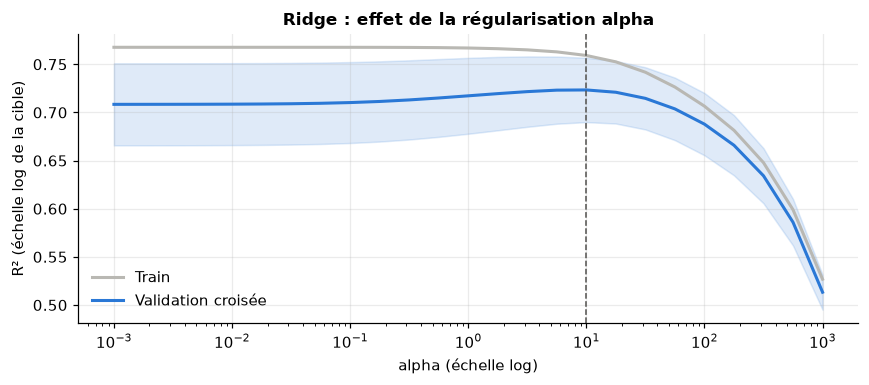

,R² train,R² test (CV),± écart-type,RMSE train,RMSE test (CV),MAE train (M kBtu),MAE test (M kBtu),MdAPE test (%)
Modèle,,,,,,,,
Régression linéaire,0.768,0.708,0.043,0.595,0.659,2.601,2.938,35.271
Ridge optimisée (alpha = 10),0.759,0.723,0.033,0.606,0.644,2.668,2.859,36.717


In [23]:
lineaire = evaluer_modele("Régression linéaire", LinearRegression())

recherche_ridge = GridSearchCV(
    pipeline(Ridge()),
    {"modele__alpha": np.logspace(-3, 3, 25)},
    cv=CV,
    scoring=SCORING,
    refit="R2",
    n_jobs=-1,
    return_train_score=True,
)
recherche_ridge.fit(X_train, y_train)
alpha = recherche_ridge.best_params_["modele__alpha"]
ridge_cv = evaluer_modele(f"Ridge optimisée (alpha = {alpha:g})", Ridge(alpha=alpha))

r = recherche_ridge.cv_results_
alphas = r["param_modele__alpha"].astype(float)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(alphas, r["mean_train_R2"], color=GRIS_MOYEN, lw=2, label="Train")
ax.plot(alphas, r["mean_test_R2"], color=BLEU, lw=2, label="Validation croisée")
ax.fill_between(
    alphas,
    r["mean_test_R2"] - r["std_test_R2"],
    r["mean_test_R2"] + r["std_test_R2"],
    color=BLEU,
    alpha=0.15,
)
ax.axvline(alpha, color=ENCRE, lw=1, ls="--")
ax.set(
    xscale="log",
    title="Ridge : effet de la régularisation alpha",
    xlabel="alpha (échelle log)",
    ylabel="R² (échelle log de la cible)",
)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / "09_ridge_alpha.png", bbox_inches="tight")
plt.show()

tableau([lineaire, ridge_cv])

**L'optimisation apporte un gain réel au modèle de référence :**
- avec `alpha` = 10, le R² en validation croisée passe de **0,708 à 0,723** (+1,5 point) ;
- le modèle devient plus stable : l'écart-type entre folds baisse de 0,043 à 0,033, et l'écart entre train et test se réduit de 0,06 à 0,04 ;
- la courbe montre l'équilibre : avec un `alpha` trop faible, le modèle colle davantage au train ; au-delà de 100, il devient trop contraint et le R² chute partout ;
- la RMSE baisse (0,659 → 0,644) alors que l'erreur médiane augmente légèrement (35 % → 37 %) : la régularisation réduit surtout les grosses erreurs.

La Ridge est donc un modèle de référence plus robuste que la régression linéaire simple.

#### Comparaison avec les autres familles de modèles

Comparaison de la référence linéaire, simple et optimisée, avec un modèle de type **SVM** (SVR) et deux modèles **à base d'arbres** (Random Forest, Gradient Boosting). Pour ces derniers, **paramètres par défaut** à cette étape, avec seulement `random_state` fixé pour la reproductibilité.

In [24]:
autres = [
    evaluer_modele(nom, m)
    for nom, m in {
        "SVR (noyau RBF)": SVR(),
        "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    }.items()
]
naive = evaluer_modele("Référence naïve", DummyRegressor())
comparaison = (
    pd.DataFrame([lineaire, ridge_cv, *autres, naive])
    .set_index("Modèle")
    .sort_values("R2 CV", ascending=False)
)
modeles = [m for m in comparaison.index if not m.startswith("Référence")]
tableau([lineaire, ridge_cv, *autres, naive]).loc[comparaison.index]

,R² train,R² test (CV),± écart-type,RMSE train,RMSE test (CV),MAE train (M kBtu),MAE test (M kBtu),MdAPE test (%)
Modèle,,,,,,,,
Ridge optimisée (alpha = 10),0.759,0.723,0.033,0.606,0.644,2.668,2.859,36.717
Gradient Boosting,0.871,0.716,0.030,0.444,0.652,1.873,2.739,35.190
SVR (noyau RBF),0.842,0.714,0.025,0.491,0.655,1.805,2.701,35.406
Régression linéaire,0.768,0.708,0.043,0.595,0.659,2.601,2.938,35.271
Random Forest,0.960,0.695,0.040,0.246,0.675,1.102,2.669,37.186
Référence naïve,0.000,-0.019,0.017,1.235,1.238,5.395,5.413,76.032


#### Visualiser les différences entre modèles

Un seul chiffre ne suffit pas pour comparer des modèles. Les graphiques suivants montrent aussi leur **stabilité** d'un fold à l'autre, leur **sur-apprentissage**, la **forme de leurs erreurs**, la part de bâtiments bien estimés et leur **coût de calcul**.

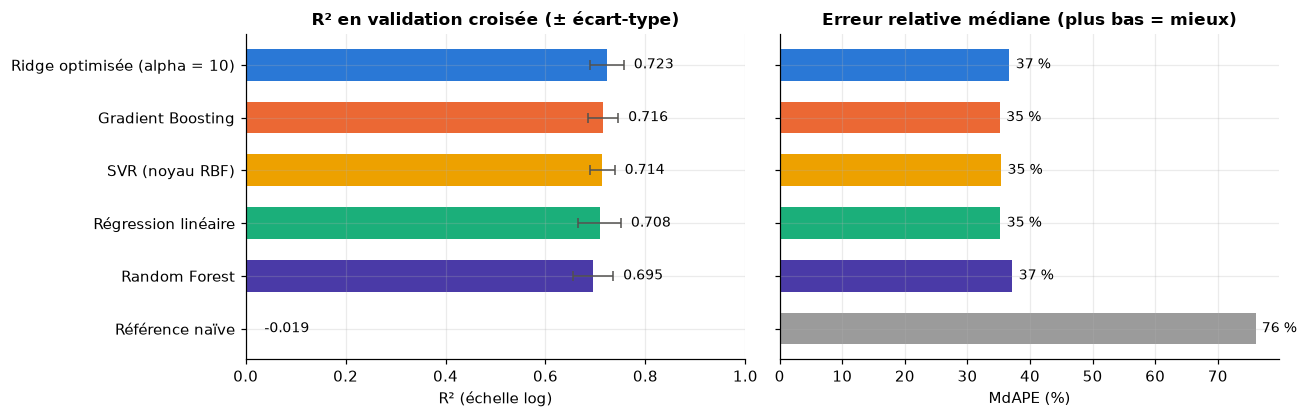

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
ordre_barres = comparaison.index[::-1]
couleurs = [couleur(m) for m in ordre_barres]
axes[0].barh(
    ordre_barres,
    comparaison.loc[ordre_barres, "R2 CV"],
    xerr=comparaison.loc[ordre_barres, "R2 écart-type"],
    color=couleurs,
    height=0.6,
    error_kw=dict(ecolor=ENCRE, lw=1, capsize=3),
)
axes[0].set(
    title="R² en validation croisée (± écart-type)",
    xlabel="R² (échelle log)",
    xlim=(0, 1),
)
axes[1].barh(
    ordre_barres,
    comparaison.loc[ordre_barres, "MdAPE_% CV"],
    color=couleurs,
    height=0.6,
)
axes[1].set(title="Erreur relative médiane (plus bas = mieux)", xlabel="MdAPE (%)")
for ax, col, fmt in [(axes[0], "R2 CV", "{:.3f}"), (axes[1], "MdAPE_% CV", "{:.0f} %")]:
    for k, m in enumerate(ordre_barres):
        v = comparaison.loc[m, col]
        decalage = comparaison.loc[m, "R2 écart-type"] + 0.02 if col == "R2 CV" else 1
        ax.text(max(v, 0) + decalage, k, fmt.format(v), va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "10_comparaison_modeles.png", bbox_inches="tight")
plt.show()

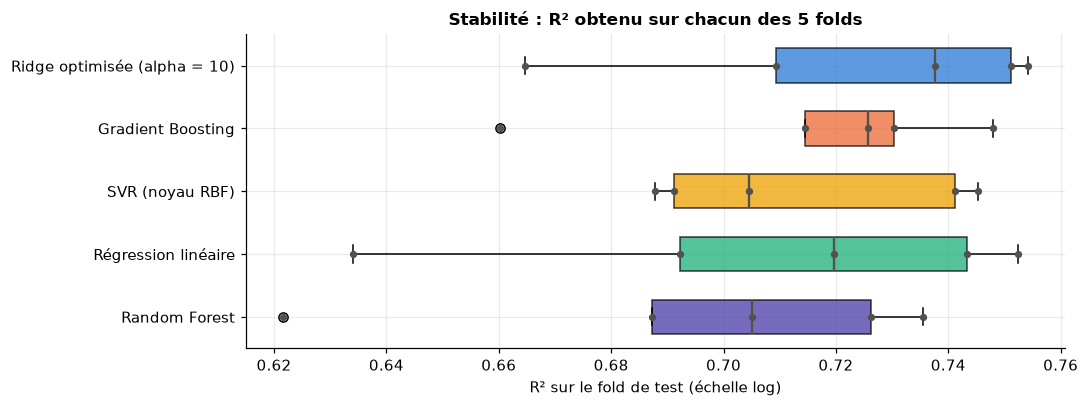

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ordre_box = modeles[::-1]
boites = ax.boxplot(
    [FOLDS[m] for m in ordre_box],
    orientation="horizontal",
    tick_labels=ordre_box,
    widths=0.55,
    patch_artist=True,
    medianprops=dict(color=ENCRE, linewidth=1.5),
)
for boite, m in zip(boites["boxes"], ordre_box):
    boite.set_facecolor(couleur(m))
    boite.set_alpha(0.75)
for k, m in enumerate(ordre_box, start=1):
    ax.scatter(FOLDS[m], np.full(len(FOLDS[m]), k), color=ENCRE, s=14, zorder=3)
ax.set(
    title="Stabilité : R² obtenu sur chacun des 5 folds",
    xlabel="R² sur le fold de test (échelle log)",
)
plt.tight_layout()
plt.savefig(FIG / "16_cv_folds_boxplot.png", bbox_inches="tight")
plt.show()

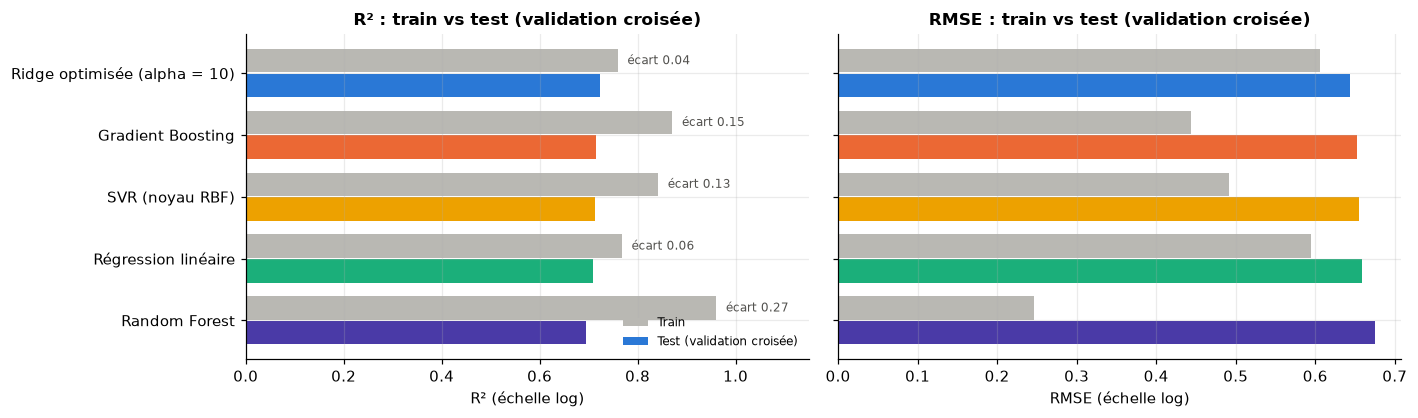

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
pos = np.arange(len(modeles))[::-1]
for ax, (metrique, titre, xlabel) in zip(
    axes,
    [
        ("R2", "R² : train vs test (validation croisée)", "R² (échelle log)"),
        ("RMSE_log", "RMSE : train vs test (validation croisée)", "RMSE (échelle log)"),
    ],
):
    ax.barh(
        pos + 0.2,
        comparaison.loc[modeles, f"{metrique} train"],
        height=0.38,
        color=GRIS_MOYEN,
        label="Train",
    )
    ax.barh(
        pos - 0.2,
        comparaison.loc[modeles, f"{metrique} CV"],
        height=0.38,
        color=[couleur(m) for m in modeles],
        label="Test (validation croisée)",
    )
    ax.set(title=titre, xlabel=xlabel)
    ax.set_yticks(pos, modeles)
for k, m in zip(pos, modeles):
    ecart = comparaison.loc[m, "R2 train"] - comparaison.loc[m, "R2 CV"]
    axes[0].text(
        comparaison.loc[m, "R2 train"] + 0.02,
        k + 0.2,
        f"écart {ecart:.2f}",
        va="center",
        fontsize=8,
        color=ENCRE,
    )
axes[0].set_xlim(0, 1.15)
axes[0].legend(frameon=False, loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "17_train_vs_cv.png", bbox_inches="tight")
plt.show()

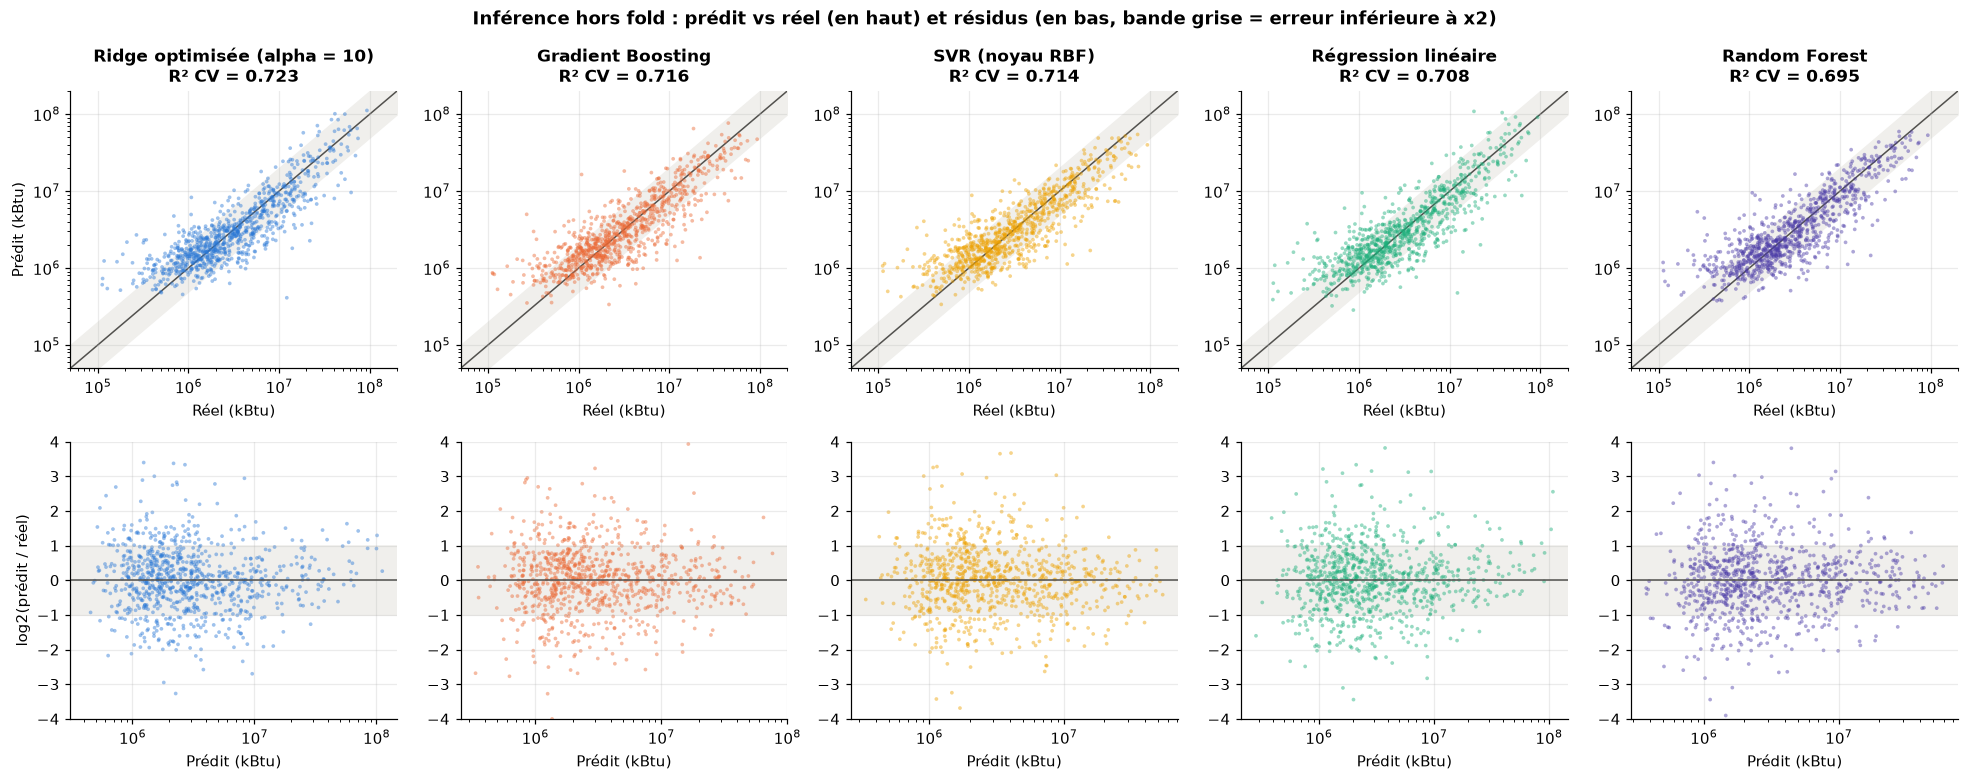

In [28]:
reel_train = np.expm1(y_train.values)
fig, axes = plt.subplots(2, len(modeles), figsize=(3.6 * len(modeles), 7.2))
for j, m in enumerate(modeles):
    pred = np.expm1(PREDICTIONS[m])
    ax = axes[0, j]
    lim = [5e4, 2e8]
    ax.fill_between(
        lim, [v / 2 for v in lim], [v * 2 for v in lim], color=GRIS, zorder=0
    )
    ax.plot(lim, lim, color=ENCRE, lw=1, zorder=1)
    ax.scatter(
        reel_train, pred, s=6, alpha=0.45, color=couleur(m), edgecolors="none", zorder=2
    )
    ax.set(
        xscale="log",
        yscale="log",
        xlim=lim,
        ylim=lim,
        title=f"{m}\nR² CV = {comparaison.loc[m, 'R2 CV']:.3f}",
    )
    ax.set_xlabel("Réel (kBtu)")
    ax.set_ylabel("Prédit (kBtu)" if j == 0 else "")
    ax = axes[1, j]
    ax.scatter(
        pred,
        np.log2(pred / reel_train),
        s=6,
        alpha=0.45,
        color=couleur(m),
        edgecolors="none",
    )
    ax.axhline(0, color=ENCRE, lw=1)
    ax.axhspan(-1, 1, color=GRIS, zorder=0)
    ax.set(xscale="log", ylim=(-4, 4), xlabel="Prédit (kBtu)")
    ax.set_ylabel("log2(prédit / réel)" if j == 0 else "")
fig.suptitle(
    "Inférence hors fold : prédit vs réel (en haut) et résidus (en bas, bande grise = erreur inférieure à x2)",
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(FIG / "18_pred_vs_reel_modeles.png", bbox_inches="tight")
plt.show()

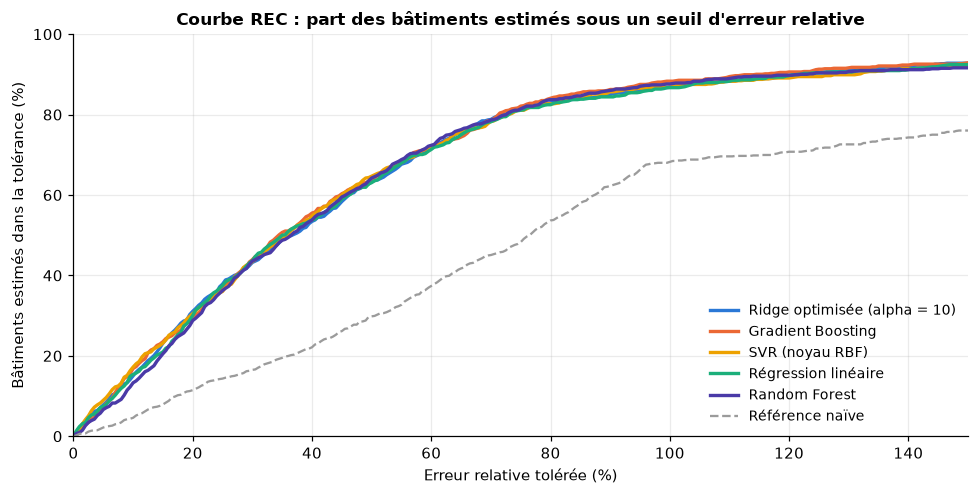

,≤ 25 %,≤ 50 %,≤ 100 % (facteur 2 en surestimation)
Modèle,,,
Ridge optimisée (alpha = 10),37.8,63.3,86.8
Gradient Boosting,36.9,64.1,88.3
SVR (noyau RBF),36.0,64.7,86.8
Régression linéaire,37.5,63.1,86.7
Random Forest,36.2,64.2,87.6
Référence naïve,14.3,29.8,68.2


In [29]:
tolerances = np.linspace(0, 150, 301)
fig, ax = plt.subplots(figsize=(9, 4.6))
part_sous = {}
for m in comparaison.index:
    erreur = np.abs(np.expm1(PREDICTIONS[m]) - reel_train) / reel_train * 100
    part = np.array([(erreur <= t).mean() * 100 for t in tolerances])
    part_sous[m] = {
        "≤ 25 %": (erreur <= 25).mean() * 100,
        "≤ 50 %": (erreur <= 50).mean() * 100,
        "≤ 100 % (facteur 2 en surestimation)": (erreur <= 100).mean() * 100,
    }
    naif = m.startswith("Référence")
    ax.plot(
        tolerances,
        part,
        color=couleur(m),
        lw=1.5 if naif else 2.2,
        ls="--" if naif else "-",
        label=m,
    )
ax.set(
    title="Courbe REC : part des bâtiments estimés sous un seuil d'erreur relative",
    xlabel="Erreur relative tolérée (%)",
    ylabel="Bâtiments estimés dans la tolérance (%)",
    xlim=(0, 150),
    ylim=(0, 100),
)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "20_courbe_rec.png", bbox_inches="tight")
plt.show()
pd.DataFrame(part_sous).T.loc[comparaison.index].round(1)

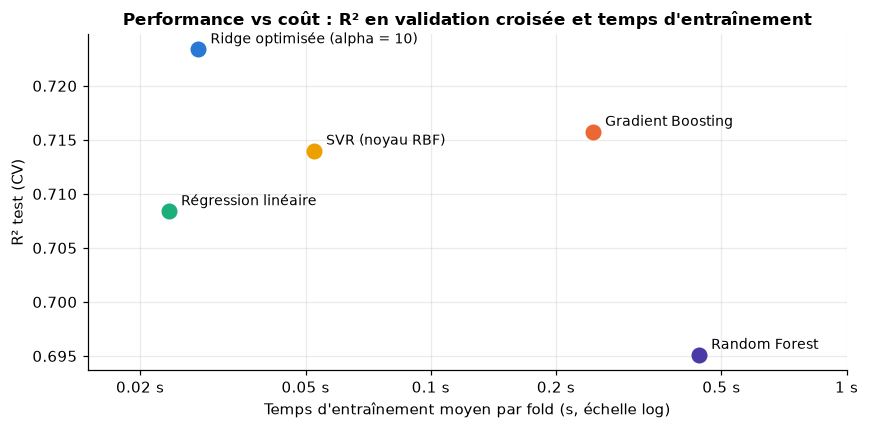

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
for m in modeles:
    t, r2 = comparaison.loc[m, "Temps d'entraînement (s)"], comparaison.loc[m, "R2 CV"]
    ax.scatter(t, r2, s=90, color=couleur(m), zorder=3)
    ax.annotate(m, (t, r2), textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.set(
    xscale="log",
    title="Performance vs coût : R² en validation croisée et temps d'entraînement",
    xlabel="Temps d'entraînement moyen par fold (s, échelle log)",
    ylabel="R² test (CV)",
)
ax.xaxis.set_major_locator(
    plt.matplotlib.ticker.FixedLocator([0.02, 0.05, 0.1, 0.2, 0.5, 1])
)
ax.xaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
ax.xaxis.set_major_formatter(
    plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g} s")
)
ax.set_xlim(0.015, 1)
plt.tight_layout()
plt.savefig(FIG / "21_temps_vs_score.png", bbox_inches="tight")
plt.show()

**Ce que montrent le tableau et les graphiques :**
- **performance** : tous les modèles battent nettement la référence naïve (R² ≈ 0, erreur médiane de 76 %) et se tiennent de près, avec un R² en validation croisée de 0,70 à 0,72 et une erreur médiane de 35 à 37 %. La **Ridge optimisée** (0,723) et le **Gradient Boosting** (0,716) arrivent en tête : ce sont les **deux finalistes**. La Ridge est déjà optimisée, le Gradient Boosting pas encore : mise à égalité à l'étape suivante ;
- **stabilité** (boxplot des folds) : tous les modèles ont un fold nettement plus difficile que les autres ; la régression linéaire simple est la plus dispersée (écart-type de 0,043), le SVR le plus régulier (0,025) ;
- **sur-apprentissage** (train vs test) : le Random Forest colle au train (R² de 0,96 en train contre 0,70 en test) ; le Gradient Boosting et le SVR sur-apprennent modérément (écarts de 0,15 et 0,13) ; la Ridge presque pas (0,04) ;
- **forme des erreurs** (prédit vs réel, résidus) : les cinq modèles ont le même profil, avec des résidus centrés sur 0 et plus dispersés pour les petits bâtiments ;
- **courbe REC** : les courbes se superposent. À tolérance égale, tous les modèles estiment la même part de bâtiments : environ 37 % à 25 % près et 64 % à 50 % près, contre 14 % et 30 % pour la référence ;
- **coût** : la Ridge est à la fois la meilleure et l'une des plus rapides (quelques centièmes de seconde par entraînement) ; les modèles à arbres demandent environ 10 fois plus de temps.

Qu'un modèle linéaire régularisé rivalise avec le boosting confirme qu'une fois la surface passée au log, la relation est surtout linéaire (surface x usage).

#### Et l'ENERGY STAR Score ?

L'ENERGY STAR Score est calculé par l'EPA **à partir de la consommation mesurée** : il n'existe donc pas pour un bâtiment qui n'a pas encore été relevé. C'est une fuite de données, donc une variable exclue. Mesure tout de même de ce qu'il apporterait, pour justifier ce choix par des chiffres.

In [31]:
preparation_es = ColumnTransformer(
    preparation.transformers
    + [
        (
            "energystar",
            make_pipeline(
                SimpleImputer(strategy="median", add_indicator=True), StandardScaler()
            ),
            ["ENERGYSTARScore"],
        ),
    ]
)
X_train_es = df.loc[X_train.index, FEATURES + ["ENERGYSTARScore"]]
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)

effet_es = pd.DataFrame(
    [
        evaluer_modele("Sans ENERGY STAR (retenu)", gb),
        evaluer_modele(
            "Avec ENERGY STAR (fuite)", gb, X=X_train_es, prep=preparation_es
        ),
    ]
).set_index("Modèle")[["R2 CV", "MdAPE_% CV"]]
print(
    f"Part de scores manquants dans le train : {X_train_es['ENERGYSTARScore'].isna().mean() * 100:.0f} %"
)
effet_es.round(3)

Part de scores manquants dans le train : 34 %


,R2 CV,MdAPE_% CV
Modèle,,
Sans ENERGY STAR (retenu),0.716,35.190
Avec ENERGY STAR (fuite),0.772,30.333


Avec l'ENERGY STAR Score, le R² gagnerait environ 6 points (0,72 → 0,77) et l'erreur médiane passerait de 35 % à 30 %. Ce gain vient justement de la fuite : le score résume l'efficacité énergétique **mesurée** du bâtiment. Il manque en plus pour un tiers des bâtiments. **Il n'est donc pas retenu** : pour un bâtiment qui n'a jamais été relevé, il n'existe pas.

### Optimisation et interprétation du modèle

#### Optimisation des deux finalistes

La Ridge est déjà optimisée. Optimisation du Gradient Boosting par `GridSearchCV`, sur **5 hyperparamètres**. Test préalable sur **10 combinaisons** tirées au hasard dans la grille (arrêt immédiat en cas d'erreur, estimation de la durée), puis lancement de la grille complète : **216 combinaisons x 5 folds**, toujours sur le train uniquement, dans la fourchette de 100 à 500 combinaisons.

| Hyperparamètre | Rôle | Valeurs testées |
|---|---|---|
| `n_estimators` | nombre d'arbres | 100, 200, 400 |
| `learning_rate` | poids de chaque nouvel arbre | 0,03, 0,05, 0,1 |
| `max_depth` | profondeur des arbres (complexité) | 2, 3, 4 |
| `min_samples_leaf` | bâtiments minimum par feuille (limite le sur-apprentissage) | 1, 5, 10, 20 |
| `subsample` | part des bâtiments tirée pour chaque arbre | 0,8, 1,0 |

In [32]:
grille = {
    "modele__n_estimators": [100, 200, 400],
    "modele__learning_rate": [0.03, 0.05, 0.1],
    "modele__max_depth": [2, 3, 4],
    "modele__min_samples_leaf": [1, 5, 10, 20],
    "modele__subsample": [0.8, 1.0],
}
# Test sur 10 combinaisons tirées dans la grille : arrêt au premier bug et estimation de la durée
test_gb = RandomizedSearchCV(
    pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    grille,
    n_iter=10,
    cv=CV,
    scoring=SCORING,
    refit="R2",
    n_jobs=-1,
    return_train_score=True,
    error_score="raise",
    random_state=RANDOM_STATE,
)
debut = time.time()
test_gb.fit(X_train, y_train)
duree = time.time() - debut
print(f"10 combinaisons testées sans erreur en {duree:.0f} s")
print(
    f"Durée estimée pour les 216 combinaisons : environ {duree * 216 / 10 / 60:.0f} min"
)
essais = pd.DataFrame(test_gb.cv_results_["params"]).rename(
    columns=lambda c: c.replace("modele__", "")
)
essais["R² train"] = test_gb.cv_results_["mean_train_R2"]
essais["R² test (CV)"] = test_gb.cv_results_["mean_test_R2"]
essais["MdAPE test (%)"] = -test_gb.cv_results_["mean_test_MdAPE_%"]
essais.round(3)

10 combinaisons testées sans erreur en 4 s
Durée estimée pour les 216 combinaisons : environ 2 min


,subsample,n_estimators,min_samples_leaf,max_depth,learning_rate,R² train,R² test (CV),MdAPE test (%)
0,1.0,200,5,4,0.10,0.950,0.707,35.795
1,1.0,200,20,4,0.10,0.894,0.686,37.551
2,0.8,100,20,4,0.05,0.797,0.684,38.910
3,1.0,200,5,3,0.10,0.907,0.722,34.935
4,1.0,200,10,2,0.03,0.767,0.705,40.407
5,1.0,200,10,3,0.05,0.842,0.724,35.508
6,0.8,200,10,3,0.10,0.892,0.721,36.706
7,1.0,100,1,2,0.05,0.763,0.698,40.387
8,1.0,100,10,4,0.10,0.883,0.722,35.909
9,1.0,100,20,4,0.05,0.805,0.694,37.729


In [33]:
recherche_gb = GridSearchCV(
    pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    grille,
    cv=CV,
    scoring=SCORING,
    refit="R2",
    n_jobs=-1,
    return_train_score=True,
)
debut = time.time()
recherche_gb.fit(X_train, y_train)
print(
    f"{len(recherche_gb.cv_results_['params'])} combinaisons testées en {time.time() - debut:.0f} s"
)
params_gb = {k.replace("modele__", ""): v for k, v in recherche_gb.best_params_.items()}
print("Meilleurs hyperparamètres :", params_gb)


def ligne_cv(nom, recherche):
    r, i = recherche.cv_results_, recherche.best_index_
    return {
        "Modèle": nom,
        "R² train": r["mean_train_R2"][i],
        "R² test (CV)": r["mean_test_R2"][i],
        "± écart-type": r["std_test_R2"][i],
        "MdAPE test (%)": -r["mean_test_MdAPE_%"][i],
    }


pd.DataFrame(
    [
        {
            "Modèle": "Régression linéaire (défaut)",
            "R² train": lineaire["R2 train"],
            "R² test (CV)": lineaire["R2 CV"],
            "± écart-type": lineaire["R2 écart-type"],
            "MdAPE test (%)": lineaire["MdAPE_% CV"],
        },
        ligne_cv(f"Ridge optimisée (alpha = {alpha:g})", recherche_ridge),
        {
            "Modèle": "Gradient Boosting (défaut)",
            "R² train": comparaison.loc["Gradient Boosting", "R2 train"],
            "R² test (CV)": comparaison.loc["Gradient Boosting", "R2 CV"],
            "± écart-type": comparaison.loc["Gradient Boosting", "R2 écart-type"],
            "MdAPE test (%)": comparaison.loc["Gradient Boosting", "MdAPE_% CV"],
        },
        ligne_cv("Gradient Boosting optimisé", recherche_gb),
    ]
).set_index("Modèle").round(3)

216 combinaisons testées en 95 s
Meilleurs hyperparamètres : {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 200, 'subsample': 0.8}


,R² train,R² test (CV),± écart-type,MdAPE test (%)
Modèle,,,,
Régression linéaire (défaut),0.768,0.708,0.043,35.271
Ridge optimisée (alpha = 10),0.759,0.723,0.033,36.717
Gradient Boosting (défaut),0.871,0.716,0.030,35.190
Gradient Boosting optimisé,0.865,0.730,0.028,35.953


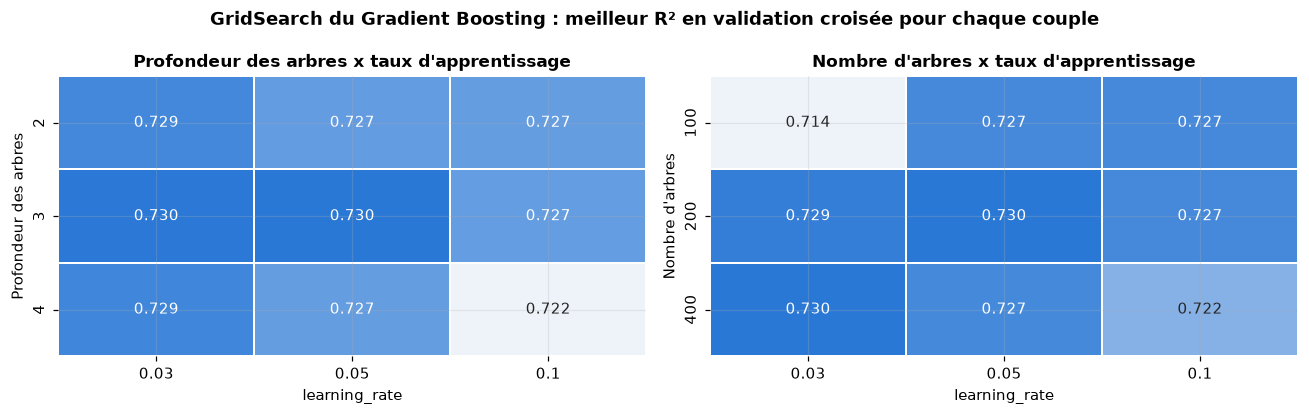

In [34]:
resultats = pd.DataFrame(recherche_gb.cv_results_)
seq = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", ["#EEF3FA", BLEU])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (lignes, titre) in zip(
    axes,
    [
        ("param_modele__max_depth", "Profondeur des arbres"),
        ("param_modele__n_estimators", "Nombre d'arbres"),
    ],
):
    pivot = resultats.pivot_table(
        index=lignes,
        columns="param_modele__learning_rate",
        values="mean_test_R2",
        aggfunc="max",
    )
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".3f",
        cmap=seq,
        cbar=False,
        linewidths=1,
        linecolor="white",
        ax=ax,
    )
    ax.set(
        title=f"{titre} x taux d'apprentissage", xlabel="learning_rate", ylabel=titre
    )
fig.suptitle(
    "GridSearch du Gradient Boosting : meilleur R² en validation croisée pour chaque couple",
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(FIG / "23_gridsearch_heatmap.png", bbox_inches="tight")
plt.show()

Après optimisation, les deux finalistes sont au coude-à-coude :
- **Gradient Boosting : 0,730 ± 0,028** (+1,4 point par rapport au défaut), avec 200 arbres, un taux d'apprentissage de 0,05, une profondeur de 3, au moins 5 bâtiments par feuille et 80 % des bâtiments tirés pour chaque arbre ;
- **Ridge : 0,723 ± 0,033**.

L'écart (0,007) est bien plus petit que l'écart-type entre folds : les deux modèles sont statistiquement à égalité.

Les heatmaps montrent un paysage **très plat** : presque toutes les combinaisons donnent entre 0,72 et 0,73, le Gradient Boosting est donc peu sensible à ses réglages. Seules deux zones dégradent un peu le score : trop peu d'arbres avec un taux d'apprentissage faible (0,714 : le modèle n'a pas fini d'apprendre), et un taux élevé avec des arbres profonds ou nombreux (0,722 : il commence à sur-apprendre).

#### Courbes d'apprentissage des deux finalistes

Une courbe d'apprentissage montre le score en fonction du nombre de bâtiments d'entraînement. Si les courbes train et validation se rejoignent, le modèle a atteint sa limite ; si l'écart reste grand, il sur-apprend ; si la courbe de validation monte encore, plus de données aideraient.

Ridge optimisée (alpha = 10)     R² validation : 0.605 (139 bâtiments) -> 0.723 (697) | écart train - validation final : 0.036


Gradient Boosting optimisé       R² validation : 0.586 (139 bâtiments) -> 0.731 (697) | écart train - validation final : 0.133


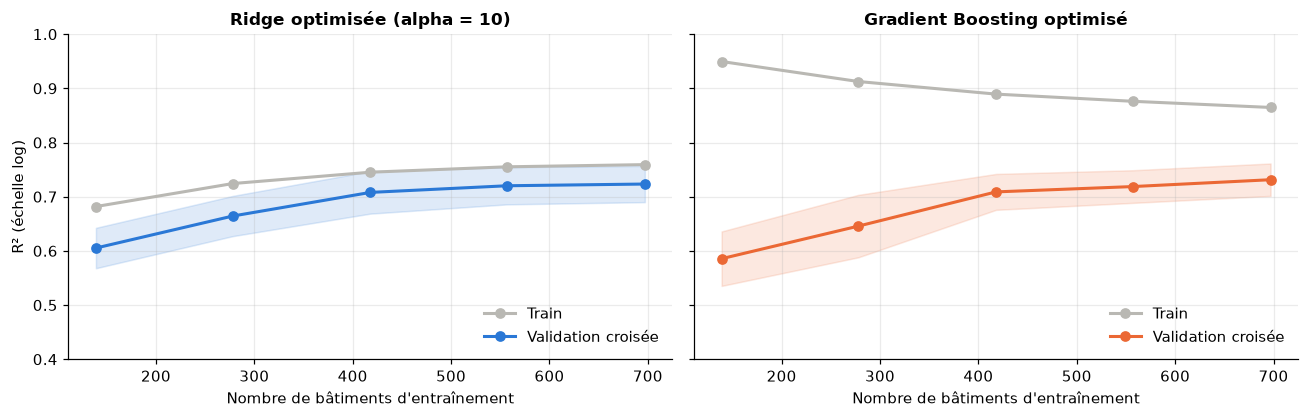

In [35]:
ridge_opt = recherche_ridge.best_estimator_
gb_opt = recherche_gb.best_estimator_

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, (nom, modele) in zip(
    axes,
    [
        (f"Ridge optimisée (alpha = {alpha:g})", ridge_opt),
        ("Gradient Boosting optimisé", gb_opt),
    ],
):
    tailles, sc_train, sc_val = learning_curve(
        modele,
        X_train,
        y_train,
        cv=CV,
        scoring="r2",
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=-1,
    )
    ax.plot(
        tailles,
        sc_train.mean(axis=1),
        color=GRIS_MOYEN,
        marker="o",
        lw=2,
        label="Train",
    )
    ax.plot(
        tailles,
        sc_val.mean(axis=1),
        color=couleur(nom),
        marker="o",
        lw=2,
        label="Validation croisée",
    )
    ax.fill_between(
        tailles,
        sc_val.mean(axis=1) - sc_val.std(axis=1),
        sc_val.mean(axis=1) + sc_val.std(axis=1),
        color=couleur(nom),
        alpha=0.15,
    )
    ax.set(title=nom, xlabel="Nombre de bâtiments d'entraînement", ylim=(0.4, 1.0))
    ax.legend(frameon=False, loc="lower right")
    print(
        f"{nom:32s} R² validation : {sc_val.mean(axis=1)[0]:.3f} ({tailles[0]} bâtiments) -> {sc_val.mean(axis=1)[-1]:.3f} ({tailles[-1]})"
        f" | écart train - validation final : {sc_train.mean(axis=1)[-1] - sc_val.mean(axis=1)[-1]:.3f}"
    )
axes[0].set_ylabel("R² (échelle log)")
plt.tight_layout()
plt.savefig(FIG / "22_learning_curves.png", bbox_inches="tight")
plt.show()

**Ce que montrent les courbes :**
- **Ridge** : les courbes train et validation se rapprochent (écart final de 0,04) et la validation plafonne autour de 0,72 : le modèle a presque atteint sa limite. Plus de données l'aideraient peu ; il faudrait plutôt des features plus riches ;
- **Gradient Boosting** : l'écart reste plus grand (0,13), signe d'un léger sur-apprentissage, mais la courbe de validation monte encore (de 0,59 à 0,73) : il profiterait davantage de données supplémentaires, par exemple d'autres années de relevés.

#### Choix du modèle et contrôle sur le jeu de validation

Le jeu de validation n'a servi ni à comparer les modèles ni à régler leurs hyperparamètres. Il sert à vérifier, sur des bâtiments jamais vus, que les deux finalistes tiennent leurs performances.

**Règle de décision :** l'objectif étant de prédire la consommation, choix du finaliste qui a le **meilleur R² en validation croisée**, l'estimation la plus fiable (5 folds sur 872 bâtiments). La validation sert à vérifier que ce choix tient sur des bâtiments jamais vus. La matrice « gros consommateurs » est une lecture complémentaire, qui ne change pas le choix.

In [36]:
controle = pd.DataFrame(
    {
        f"Ridge optimisée (alpha = {alpha:g})": metriques(
            y_val, ridge_opt.predict(X_val)
        ),
        "Gradient Boosting optimisé": metriques(y_val, gb_opt.predict(X_val)),
    }
).T
print(
    f"Gros consommateurs dans la validation : {int((y_val >= SEUIL).sum())} sur {len(y_val)}"
)
controle[
    ["R2", "RMSE_log", "MdAPE_%", "TP", "FN", "FP", "TN", "Précision", "Rappel"]
].astype(float).round(3)

Gros consommateurs dans la validation : 71 sur 291


,R2,RMSE_log,MdAPE_%,TP,FN,FP,TN,Précision,Rappel
Ridge optimisée (alpha = 10),0.727,0.646,37.184,47.0,24.0,10.0,210.0,0.825,0.662
Gradient Boosting optimisé,0.727,0.646,39.615,55.0,16.0,9.0,211.0,0.859,0.775


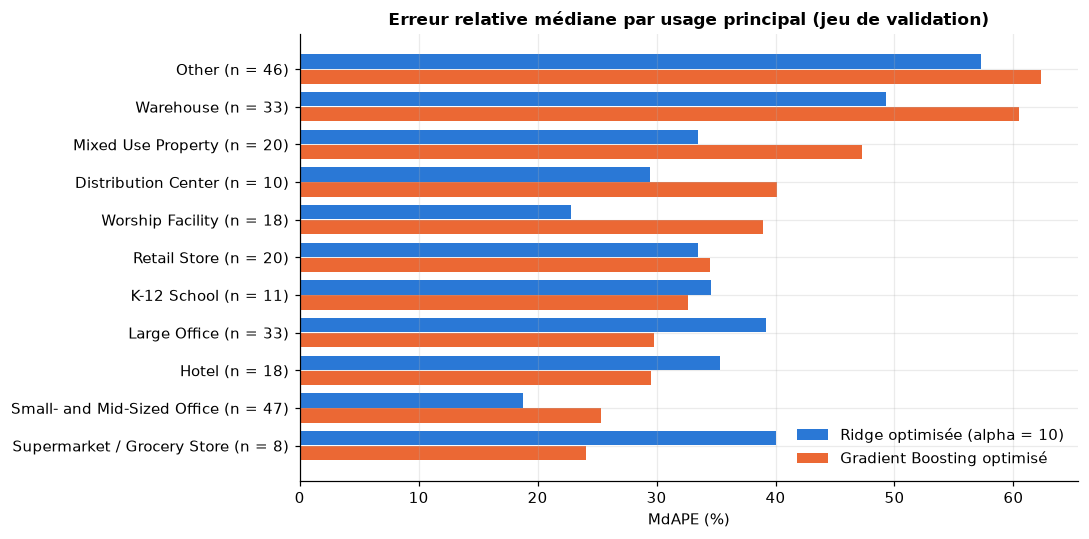

,n,Ridge optimisée (alpha = 10),Gradient Boosting optimisé
Usage,,,
Supermarket / Grocery Store,8,40.1,24.0
Small- and Mid-Sized Office,47,18.8,25.4
Hotel,18,35.3,29.5
Large Office,33,39.2,29.8
K-12 School,11,34.5,32.7
Retail Store,20,33.5,34.5
Worship Facility,18,22.8,39.0
Distribution Center,10,29.4,40.1
Mixed Use Property,20,33.5,47.2


In [37]:
val = pd.DataFrame(
    {"Usage": X_val["PrimaryPropertyType"].values, "reel": np.expm1(y_val.values)}
)
finalistes = {
    f"Ridge optimisée (alpha = {alpha:g})": ridge_opt,
    "Gradient Boosting optimisé": gb_opt,
}
for nom, modele in finalistes.items():
    val[nom] = np.abs(np.expm1(modele.predict(X_val)) - val["reel"]) / val["reel"] * 100
par_usage = val.groupby("Usage").agg(
    n=("reel", "size"), **{nom: (nom, "median") for nom in finalistes}
)
par_usage = par_usage[par_usage["n"] >= 8].sort_values("Gradient Boosting optimisé")

fig, ax = plt.subplots(figsize=(10, 5))
pos = np.arange(len(par_usage))
for decalage, nom in zip([0.2, -0.2], finalistes):
    ax.barh(pos + decalage, par_usage[nom], height=0.38, color=couleur(nom), label=nom)
ax.set_yticks(pos, [f"{u} (n = {n})" for u, n in zip(par_usage.index, par_usage["n"])])
ax.set(
    title="Erreur relative médiane par usage principal (jeu de validation)",
    xlabel="MdAPE (%)",
)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "24_erreur_par_usage.png", bbox_inches="tight")
plt.show()
par_usage.round(1)

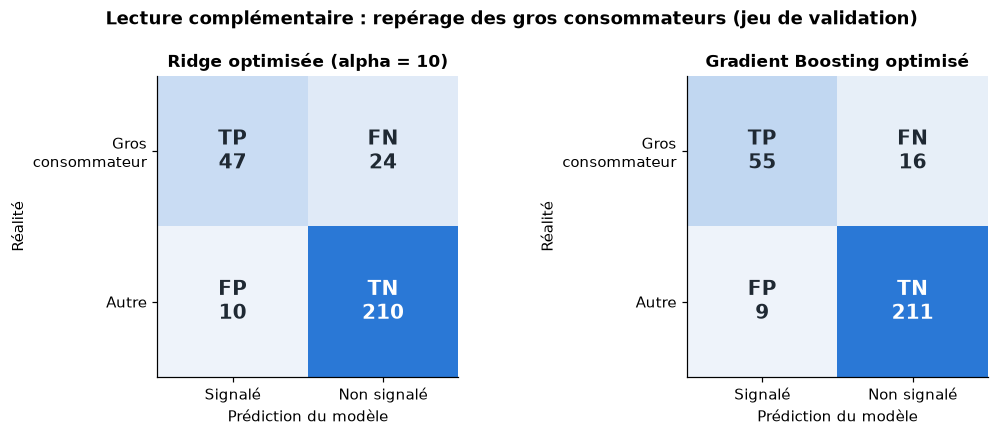

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nom, modele) in zip(axes, finalistes.items()):
    matrice(ax, y_val, modele.predict(X_val), nom)
fig.suptitle(
    "Lecture complémentaire : repérage des gros consommateurs (jeu de validation)",
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(FIG / "15_matrices_validation.png", bbox_inches="tight")
plt.show()

**Résultat :**
- **choix :** le Gradient Boosting optimisé a le meilleur R² en validation croisée (0,730 contre 0,723) : **il est retenu** ;
- **contrôle :** sur la validation, les deux finalistes obtiennent exactement le même R² (0,727). Le Gradient Boosting tient donc sa performance sur des bâtiments jamais vus ; la Ridge a une erreur médiane un peu plus faible (37 % contre 40 %) ;
- **par usage**, les deux modèles se complètent : le Gradient Boosting est nettement meilleur sur les bâtiments complexes ou très consommateurs (supermarchés, hôtels, grands bureaux), la Ridge sur les bâtiments plus simples (petits bureaux, lieux de culte, centres de distribution, usages mixtes). Les deux peinent sur la catégorie fourre-tout « Other » et sur les entrepôts ;
- **lecture complémentaire :** le Gradient Boosting repère aussi plus de gros consommateurs (55 sur 71 contre 47, précision de 0,86).

La Ridge reste un choix tout aussi défendable, plus simple à expliquer. Leur complémentarité par usage ouvre une piste : combiner les deux modèles.

#### Évaluation finale sur le jeu de test (une seule fois)

Réentraînement du modèle retenu sur train + validation (80 % des données), puis évaluation **une seule fois** sur le jeu de test.

In [39]:
X_app = pd.concat([X_train, X_val])
y_app = pd.concat([y_train, y_val])
modele_final = pipeline(
    GradientBoostingRegressor(random_state=RANDOM_STATE, **params_gb)
).fit(X_app, y_app)

pred_test = modele_final.predict(X_test)
resultat_test = pd.Series(metriques(y_test, pred_test), name="Test").to_frame().T
resultat_test.astype(float).round(3)

,R2,RMSE_log,MAE_kBtu,MdAPE_%,TP,FN,FP,TN,Précision,Rappel
Test,0.758,0.578,2275227.289,36.649,53.0,17.0,10.0,211.0,0.841,0.757


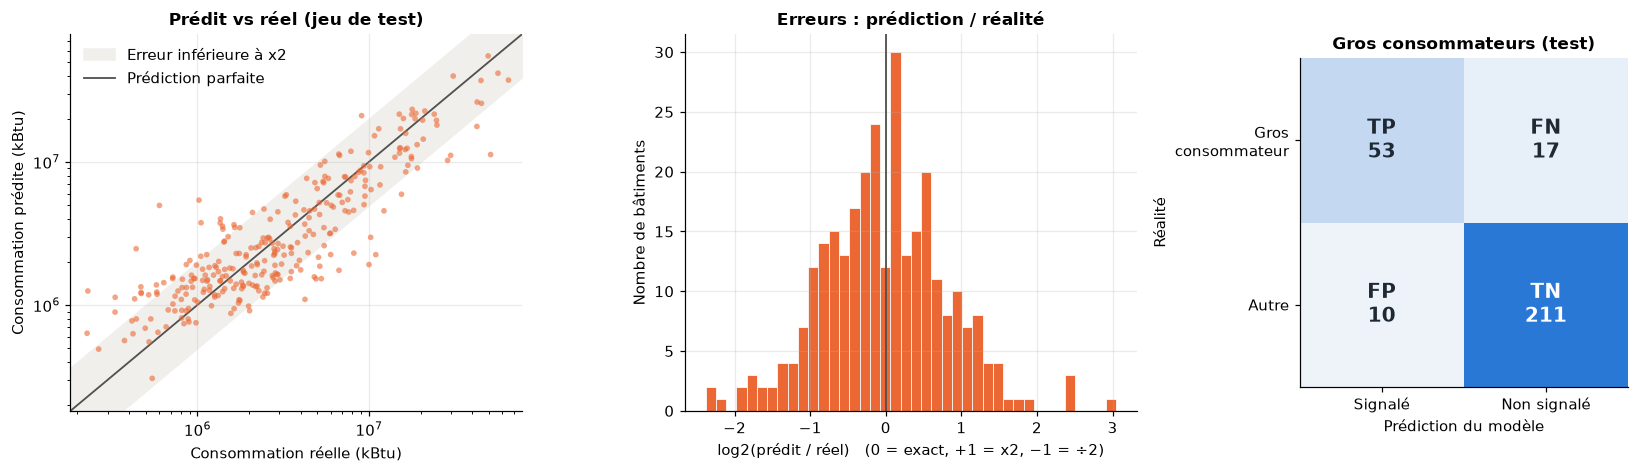

Bâtiments estimés à moins de 25 % près : 36 %
Bâtiments estimés à un facteur 2 près  : 79 %
Au-delà d'un facteur 2 : 30 surestimations et 30 sous-estimations


In [40]:
reel, pred = np.expm1(y_test), np.expm1(pred_test)
ratio = pred / reel

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1.1, 0.8]}
)
lim = [min(reel.min(), pred.min()) * 0.8, max(reel.max(), pred.max()) * 1.2]
axes[0].fill_between(
    lim,
    [v / 2 for v in lim],
    [v * 2 for v in lim],
    color=GRIS,
    zorder=0,
    label="Erreur inférieure à x2",
)
axes[0].plot(lim, lim, color=ENCRE, lw=1.2, zorder=1, label="Prédiction parfaite")
axes[0].scatter(reel, pred, s=14, alpha=0.6, color=ORANGE, edgecolors="none", zorder=2)
axes[0].set(
    xscale="log",
    yscale="log",
    xlim=lim,
    ylim=lim,
    title="Prédit vs réel (jeu de test)",
    xlabel="Consommation réelle (kBtu)",
    ylabel="Consommation prédite (kBtu)",
)
axes[0].legend(loc="upper left", frameon=False)

axes[1].hist(np.log2(ratio), bins=40, color=ORANGE, edgecolor="white", linewidth=0.5)
axes[1].axvline(0, color=ENCRE, lw=1.2)
axes[1].set(
    title="Erreurs : prédiction / réalité",
    xlabel="log2(prédit / réel)   (0 = exact, +1 = x2, −1 = ÷2)",
    ylabel="Nombre de bâtiments",
)
matrice(axes[2], y_test, pred_test, "Gros consommateurs (test)")
plt.tight_layout()
plt.savefig(FIG / "11_evaluation_test.png", bbox_inches="tight")
plt.show()

print(
    f"Bâtiments estimés à moins de 25 % près : {(np.abs(ratio - 1) < 0.25).mean() * 100:.0f} %"
)
print(
    f"Bâtiments estimés à un facteur 2 près  : {((ratio > 0.5) & (ratio < 2)).mean() * 100:.0f} %"
)
print(
    f"Au-delà d'un facteur 2 : {(ratio >= 2).sum()} surestimations et {(ratio <= 0.5).sum()} sous-estimations"
)

Sur le jeu de test, le modèle obtient un **R² de 0,76** (en log), cohérent avec la validation croisée (0,73) : il n'y a pas de sur-apprentissage caché.

**En termes métier :**
- **l'erreur médiane est d'environ 37 %** : la moitié des bâtiments est estimée avec un écart inférieur à ce niveau ;
- **8 bâtiments sur 10 sont estimés à un facteur 2 près** (79 %), et les erreurs sont équilibrées (30 surestimations et 30 sous-estimations au-delà de ce facteur) ;
- en lecture complémentaire, **53 gros consommateurs sur 70 sont repérés** (rappel de 0,76), avec 10 fausses alertes (précision de 0,84) ;
- l'erreur absolue moyenne est de 2,3 millions de kBtu pour une consommation médiane de 2,6 millions : elle est tirée par les grands bâtiments ;
- les erreurs sont les plus fortes pour les **petits bâtiments** et pour les catégories hétérogènes (**« Other », entrepôts, centres de distribution, usages mixtes**).

Ce niveau de précision permet d'**estimer l'ordre de grandeur** de la consommation d'un bâtiment jamais relevé, et donc de **prioriser** les relevés. Il ne remplace pas un relevé.

#### Interprétation : quelles features pèsent le plus ?

L'étude de l'importance des features n'a de sens qu'**après** l'optimisation, sur le modèle final : un autre modèle, même aussi performant, peut avoir des importances très différentes. Le meilleur modèle est un modèle à base d'arbres : utilisation de sa **feature importance** native, croisée avec deux autres méthodes :
1. **l'importance native** du Gradient Boosting (gain moyen des divisions de chaque colonne) ;
2. **l'importance par permutation** sur le jeu de test : une feature est mélangée, puis la perte de R² est mesurée. Elle porte sur les 14 features d'origine, donc chaque catégorielle compte comme une seule feature ;
3. **SHAP**, qui donne le sens de l'effet de chaque feature, bâtiment par bâtiment.

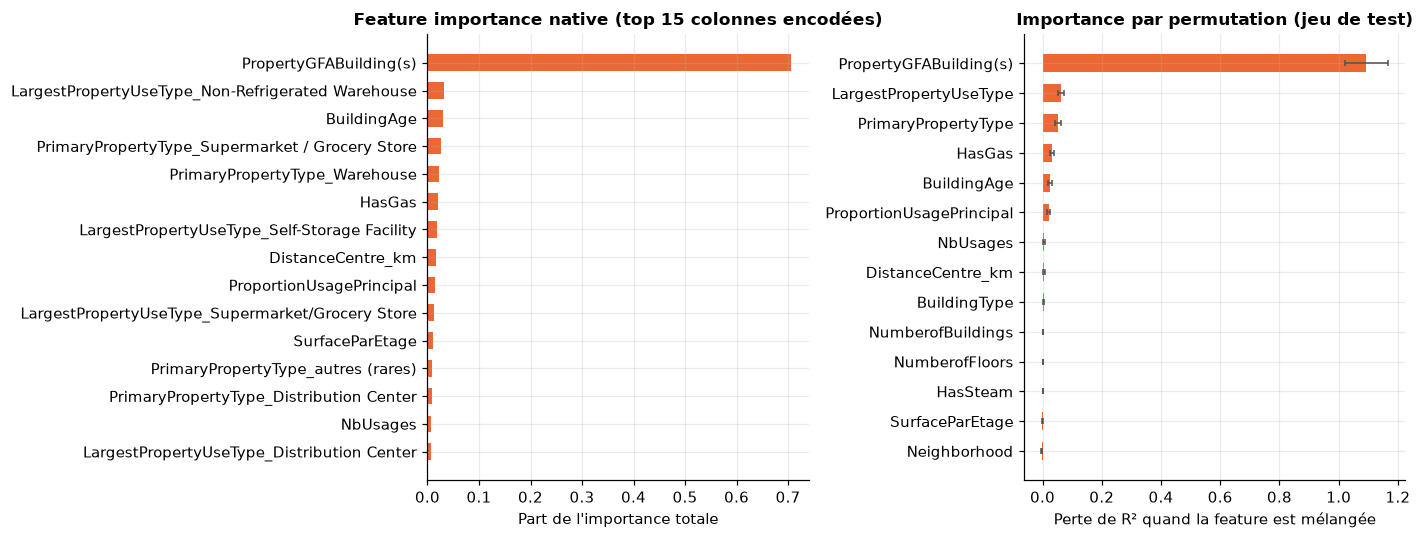

,moyenne,ecart
PropertyGFABuilding(s),1.094,0.073
LargestPropertyUseType,0.062,0.010
PrimaryPropertyType,0.053,0.011
HasGas,0.033,0.006
BuildingAge,0.024,0.006
ProportionUsagePrincipal,0.021,0.004
NbUsages,0.005,0.004
DistanceCentre_km,0.005,0.003


In [41]:
noms = modele_final.named_steps["prep"].get_feature_names_out().astype(str)
noms = (
    pd.Series(noms)
    .str.replace(r"^(log|num|bin|cat)__", "", regex=True)
    .str.replace("infrequent_sklearn", "autres (rares)")
    .values
)
imp_native = pd.Series(
    modele_final.named_steps["modele"].feature_importances_, index=noms
).sort_values()

perm = permutation_importance(
    modele_final,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
imp_perm = pd.DataFrame(
    {"moyenne": perm.importances_mean, "ecart": perm.importances_std},
    index=X_test.columns,
).sort_values("moyenne")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top = imp_native.tail(15)
axes[0].barh(top.index, top.values, color=ORANGE, height=0.6)
axes[0].set(
    title="Feature importance native (top 15 colonnes encodées)",
    xlabel="Part de l'importance totale",
)
axes[1].barh(
    imp_perm.index,
    imp_perm["moyenne"],
    xerr=imp_perm["ecart"],
    color=ORANGE,
    height=0.6,
    error_kw=dict(ecolor=ENCRE, lw=1, capsize=2),
)
axes[1].set(
    title="Importance par permutation (jeu de test)",
    xlabel="Perte de R² quand la feature est mélangée",
)
plt.tight_layout()
plt.savefig(FIG / "12_importance_features.png", bbox_inches="tight")
plt.show()
imp_perm.sort_values("moyenne", ascending=False).round(3).head(8)

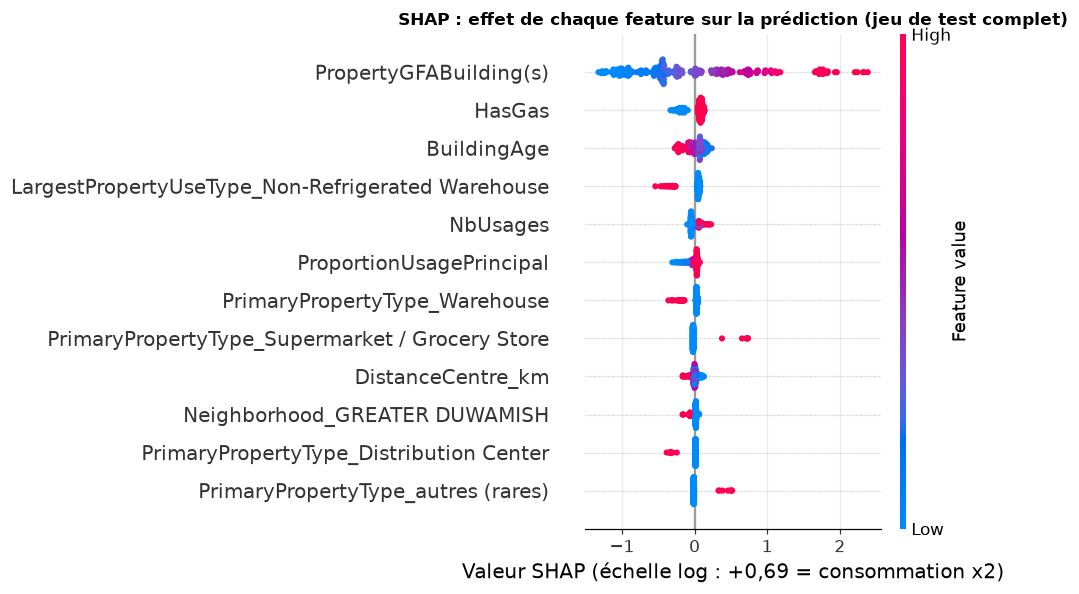

,|SHAP| moyen,Facteur multiplicatif moyen
PropertyGFABuilding(s),0.708,2.03
HasGas,0.113,1.12
BuildingAge,0.101,1.11
LargestPropertyUseType_Non-Refrigerated Warehouse,0.088,1.09
NbUsages,0.057,1.06
ProportionUsagePrincipal,0.048,1.05
PrimaryPropertyType_Warehouse,0.047,1.05
PrimaryPropertyType_Supermarket / Grocery Store,0.033,1.03


In [42]:
X_test_enc = pd.DataFrame(
    modele_final[:-1].transform(X_test), columns=noms, index=X_test.index
)
explainer = shap.TreeExplainer(modele_final.named_steps["modele"])
valeurs_shap = explainer.shap_values(X_test_enc)

shap.summary_plot(
    valeurs_shap, X_test_enc, max_display=12, show=False, plot_size=(9, 5.5)
)
plt.title("SHAP : effet de chaque feature sur la prédiction (jeu de test complet)")
plt.xlabel("Valeur SHAP (échelle log : +0,69 = consommation x2)")
plt.tight_layout()
plt.savefig(FIG / "13_shap_summary.png", bbox_inches="tight")
plt.show()

effet = (
    pd.Series(np.abs(valeurs_shap).mean(axis=0), index=noms)
    .sort_values(ascending=False)
    .head(8)
)
pd.DataFrame(
    {
        "|SHAP| moyen": effet.round(3),
        "Facteur multiplicatif moyen": np.exp(effet).round(2),
    }
)

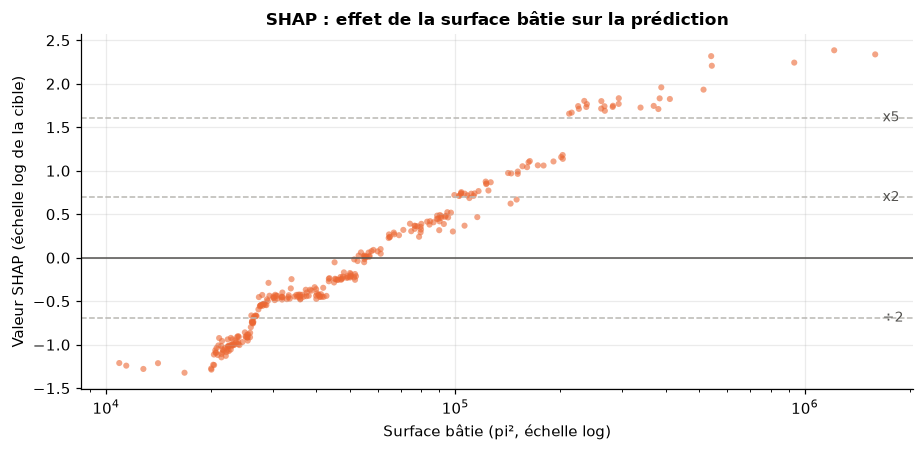

Effet de la surface : de ÷3.8 à x10.9


In [43]:
j = list(noms).index("PropertyGFABuilding(s)")
surface = df.loc[X_test.index, "PropertyGFABuilding(s)"]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.scatter(
    surface, valeurs_shap[:, j], s=16, alpha=0.6, color=ORANGE, edgecolors="none"
)
ax.axhline(0, color=ENCRE, lw=1)
for niveau, texte in [(np.log(2), "x2"), (-np.log(2), "÷2"), (np.log(5), "x5")]:
    ax.axhline(niveau, color=GRIS_MOYEN, lw=1, ls="--")
    ax.text(surface.max() * 1.05, niveau, texte, va="center", fontsize=9, color=ENCRE)
ax.set(
    xscale="log",
    title="SHAP : effet de la surface bâtie sur la prédiction",
    xlabel="Surface bâtie (pi², échelle log)",
    ylabel="Valeur SHAP (échelle log de la cible)",
)
plt.tight_layout()
plt.savefig(FIG / "25_shap_dependance_surface.png", bbox_inches="tight")
plt.show()
print(
    f"Effet de la surface : de ÷{np.exp(-valeurs_shap[:, j].min()):.1f} à x{np.exp(valeurs_shap[:, j].max()):.1f}"
)

**Comment lire SHAP avec une cible en log :** une valeur SHAP de +0,69 multiplie la consommation prédite par e^0,69 ≈ 2 ; une valeur de −0,69 la divise par 2. Dans le summary plot, chaque point est un bâtiment du jeu de test, et la couleur indique la valeur de la feature (rouge = élevée, bleu = faible).

**Points clés :**
- la **surface bâtie domine largement** : selon la taille, elle divise la prédiction jusqu'à environ 3,8 (petits bâtiments) ou la multiplie jusqu'à environ 11 (très grands bâtiments). Le graphique de dépendance montre une relation régulière et croissante ;
- le **raccordement au gaz** augmente la prédiction d'environ 9 % ;
- l'**âge** a un effet modéré : à caractéristiques égales, les bâtiments anciens sont prédits un peu moins consommateurs. Interprétation prudente : SHAP décrit le modèle, pas une causalité ;
- l'**usage** joue dans les deux sens : être un entrepôt réduit la prédiction d'environ 30 %, être un supermarché la multiplie presque par 2.

L'importance par permutation confirme ce classement : surface, puis plus grand usage et usage principal, puis gaz, âge et part de l'usage principal.

Hotel de 35,770 pi², construit il y a 88 ans
Réel : 2,640,980 kBtu  |  Prédit : 2,891,214 kBtu


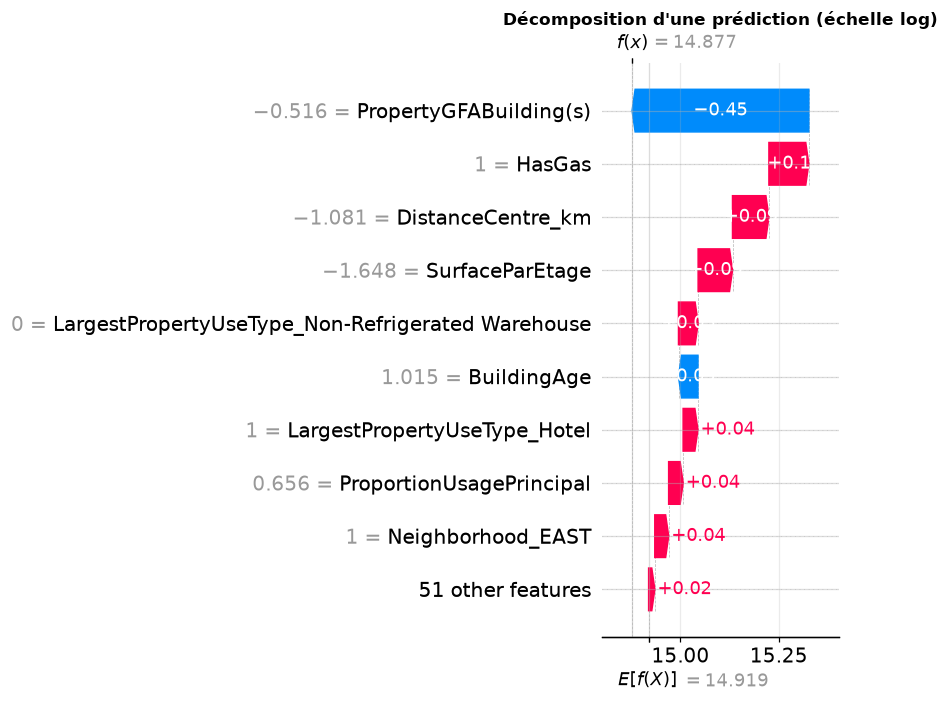

In [44]:
# Explication d'une prédiction individuelle : le bâtiment le plus proche de la médiane du test
idx = int(np.argmin(np.abs(y_test.values - y_test.median())))
batiment = df.loc[X_test.index[idx]]
print(
    f"{batiment['PrimaryPropertyType']} de {batiment['PropertyGFABuilding(s)']:,.0f} pi², construit il y a {batiment['BuildingAge']:.0f} ans"
)
print(
    f"Réel : {np.expm1(y_test.iloc[idx]):,.0f} kBtu  |  Prédit : {np.expm1(pred_test[idx]):,.0f} kBtu"
)

explication = shap.Explanation(
    values=valeurs_shap[idx],
    base_values=float(np.ravel(explainer.expected_value)[0]),
    data=X_test_enc.iloc[idx].values,
    feature_names=list(noms),
)
shap.plots.waterfall(explication, max_display=10, show=False)
plt.title("Décomposition d'une prédiction (échelle log)")
plt.tight_layout()
plt.savefig(FIG / "14_shap_waterfall.png", bbox_inches="tight")
plt.show()

#### Utilisation du modèle sur un nouveau bâtiment

Comme toute la préparation est dans le `Pipeline`, le modèle sauvegardé s'applique **directement aux données brutes** d'un bâtiment. Pour recharger le fichier dans une autre session, la classe `ImputationEtages` doit être définie avant le `joblib.load`.

In [45]:
chemin = MODELS / "pipeline_gradient_boosting_191026.joblib"
joblib.dump(modele_final, chemin)

modele_charge = joblib.load(chemin)
nouveaux = X_test.head(5)  # 5 bâtiments au format brut
estimation = np.expm1(modele_charge.predict(nouveaux))
pd.DataFrame(
    {
        "Usage": nouveaux["PrimaryPropertyType"].values,
        "Surface (pi²)": nouveaux["PropertyGFABuilding(s)"].values,
        "Réel (kBtu)": np.expm1(y_test.head(5)).round(0).values,
        "Estimé (kBtu)": estimation.round(0),
        "Écart (%)": ((estimation / np.expm1(y_test.head(5).values) - 1) * 100).round(
            0
        ),
    }
)

,Usage,Surface (pi²),Réel (kBtu),Estimé (kBtu),Écart (%)
0,Other,30160,1045838.0,2190146.0,109.0
1,Distribution Center,36498,520012.0,1177572.0,126.0
2,Small- and Mid-Sized Office,89355,4178234.0,4617404.0,11.0
3,Worship Facility,26440,719905.0,1015869.0,41.0
4,Large Office,261722,17750994.0,21433585.0,21.0


#### Conclusion

**Réponse à la question :** oui, à partir de ses seules caractéristiques structurelles, la consommation totale d'énergie d'un bâtiment non résidentiel jamais relevé peut être estimée. L'erreur médiane est d'environ 37 %, et 8 bâtiments sur 10 sont estimés à un facteur 2 près.

| | Résultat |
|---|---|
| Données | 1 454 bâtiments non résidentiels, 14 features structurelles, **aucune information issue du relevé** |
| Protocole | 60 / 20 / 20 stratifié, validation croisée à 5 folds, test utilisé une seule fois |
| Modèle de référence | régression linéaire 0,708 → Ridge optimisée 0,723 en validation croisée : l'optimisation apporte +1,5 point |
| Comparaison | 4 familles de modèles entre 0,70 et 0,72 ; finalistes : Ridge et Gradient Boosting |
| Choix final | Gradient Boosting optimisé, meilleur R² en validation croisée (0,730 contre 0,723 pour la Ridge, écart dans le bruit) ; même R² que la Ridge sur la validation (0,727) |
| Performance finale (test) | R² = 0,76 (log), erreur médiane de 37 %, 79 % des bâtiments à un facteur 2 près |
| Lecture métier (test) | 53 gros consommateurs sur 70 repérés, avec 10 fausses alertes |
| Facteurs principaux | surface bâtie ≫ usage du bâtiment > raccordement au gaz, âge |



**Limites et pistes :**
- une seule année de relevés (2016) : les courbes d'apprentissage montrent que le Gradient Boosting profiterait de données supplémentaires ;
- les petits bâtiments et les catégories hétérogènes (« Other », usages mixtes, entrepôts) restent difficiles à prédire : un descriptif plus fin des usages aiderait ;
- la Ridge et le Gradient Boosting se complètent selon l'usage : combiner leurs prédictions est une piste d'amélioration ;
- 17 gros consommateurs sur 70 restent ratés : abaisser le seuil de décision augmenterait le rappel, au prix de davantage de fausses alertes ;
- l'ENERGY STAR Score apporterait environ 6 points de R², mais seulement pour des bâtiments déjà relevés : il pourrait servir dans un second modèle, de suivi des bâtiments existants.